# Введение в простые числа

Введение в вычислительную работу с простыми числами: организация накопительной библиотеки `crypto_math`, проверка простоты перебором делителей и анализ её сложности, решето Эратосфена и его оптимизация, вычислительное исследование распределения простых чисел, функции $\pi(x)$, асимптотического закона распределения простых чисел и промежутков между соседними простыми числами.

**Выполненное решение.** Заполнены задания 1–19, практики, исследования и Challenge. Исходный текст заданий сохранён; цветные блоки адаптированы для тёмной темы. Запускать ячейки сверху вниз. Корень курса — папка с этим ноутбуком, pyproject.toml, crypto_math и tests. Время измерений зависит от компьютера. Дополнительная сверка с SageMath выполняется только в соответствующей среде.


# 1. Создание накопительной библиотеки `crypto_math`

В Notebook 1 мы вывели, реализовали и протестировали базовые алгоритмы теории чисел. Начиная с Notebook 2 эти алгоритмы должны стать **переиспользуемым математическим инструментарием**.

Цель этого задания — организовать единую библиотеку `crypto_math`, которая будет использоваться во всех последующих ноутбуках курса и постепенно расширяться вместе с ним.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Создание накопительной библиотеки `crypto_math`

Создайте в корне курса единый устанавливаемый Python-пакет `crypto_math`.

Перенесите в него проверенные функции Notebook 1:

`random_exact_bits`, `divides`, `gcd`, `extended_gcd`, `solve_linear_diophantine`, `mod_inverse`, `solve_linear`, `mod_pow`, `crt`, `garner_crt`.

Библиотека должна:

1. находиться **в корне курса**, а не внутри каталога отдельного ноутбука;
2. устанавливаться в editable-режиме;
3. импортироваться из Notebook 2 и последующих ноутбуков без изменения `sys.path`;
4. иметь единый каталог тестов;
5. расширяться тематическими модулями только после того, как соответствующие алгоритмы выведены, реализованы и протестированы в курсе.

Задание выполняйте по нижеприведенным шагам.
</div>

## Шаг 1. Создайте общий каталог курса

Ноутбуки разных тем не должны содержать собственные копии `crypto_math`.

Создайте один корневой каталог курса, например:

```text
PKC_Course/
```

Рекомендуемая структура:

```text
PKC_Course/
│
├── crypto_math/
├── tests/
│
├── 1/
│   └── 01_2026.ipynb
│
├── 2/
│   └── 02_2026.ipynb
│
├── ...
└── pyproject.toml
```

Каталоги `1/`, `2/`, ... содержат последовательные ноутбуки курса.

Библиотека `crypto_math` располагается **на одном уровне с ними**.

Это даёт единственный актуальный экземпляр каждой функции. Если позднее будет исправлена реализация `mod_pow`, исправление автоматически относится ко всему курсу, а не к одной случайной копии библиотеки.

## Шаг 2. Создайте структуру библиотеки

В корне `PKC_Course` создайте каталог `crypto_math/` с пока пустыми файлами `number_theory.py` и `__init__.py`:

```text
crypto_math/
├── __init__.py
└── number_theory.py
```

## Шаг 3. Перенесите результаты Notebook 1

В файл

```text
crypto_math/number_theory.py
```

перенесите проверенные реализации:

```python
random_exact_bits
divides
gcd
extended_gcd
solve_linear_diophantine
mod_inverse
solve_linear
mod_pow
crt
garner_crt
```

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Разделение ролей.</strong>

Notebook хранит вывод, доказательства, объяснения, эксперименты и benchmark.

`crypto_math` хранит проверенные переиспользуемые алгоритмы.

</div>

## Шаг 4. Наполнение `__init__.py`

Файл

```text
crypto_math/__init__.py
```

задаёт публичный интерфейс пакета на текущем этапе курса:

```python
from .number_theory import (
    random_exact_bits,
    divides,
    gcd,
    extended_gcd,
    solve_linear_diophantine,
    mod_inverse,
    solve_linear,
    mod_pow,
    crt,
    garner_crt,
)

__all__ = [
    "random_exact_bits",
    "divides",
    "gcd",
    "extended_gcd",
    "solve_linear_diophantine",
    "mod_inverse",
    "solve_linear",
    "mod_pow",
    "crt",
    "garner_crt",
]
```

После этого возможен импорт

```python
from crypto_math import gcd
```

Однако по мере роста курса предпочтительны явные тематические импорты:

```python
from crypto_math.number_theory import gcd, mod_inverse, mod_pow
```

Так по самому импорту видно, из какого математического слоя происходит используемый алгоритм.

## Шаг 5. Создайте `pyproject.toml`

Теперь у нас есть каталог `crypto_math` с Python-файлами, но сам по себе каталог ещё не является **установленным пакетом** для выбранного Python-окружения.

Чтобы `pip` понимал, что именно нужно установить, в корне `PKC_Course`, рядом с каталогами `crypto_math/`, `1/`, `2/` и `tests/`, создайте файл

```text
pyproject.toml
```

со следующим содержимым:

```toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "crypto-math-course"
version = "0.1.0"
description = "Educational library for the asymmetric cryptography course"
requires-python = ">=3.10"
dependencies = []

[project.optional-dependencies]
test = [
    "pytest>=8",
    "hypothesis>=6",
]

[tool.pytest.ini_options]
testpaths = ["tests"]
```

`pyproject.toml` — это описание Python-проекта. В частности, из него инструменты установки узнают имя проекта, требуемую версию Python и дополнительные зависимости.

Здесь важно различать два имени:

- `crypto-math-course` — имя **проекта**, которое видит `pip`;
- `crypto_math` — имя **Python-пакета**, которое мы пишем в `import`.

Поэтому команда установки будет работать с проектом `crypto-math-course`, а в программе мы продолжим писать, например,

```python
from crypto_math.number_theory import gcd
```

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что мы сейчас сделали?</strong>

Мы не установили библиотеку. Мы только описали проект так, чтобы на следующем шаге `pip` смог корректно связать каталог `crypto_math/` с выбранным Python-окружением.

</div>

## Шаг 6. Установите библиотеку в Linux

Установка Python-пакета всегда происходит **в конкретное Python-окружение**. Это существенно: на одном компьютере могут одновременно существовать системный Python, виртуальное окружение, Conda/SageMath и отдельный Python, которым пользуется Jupyter.

Нам нужно установить `crypto_math` именно туда, откуда её будет импортировать Notebook 2.

### 6.1. Сначала узнайте Python текущего Jupyter kernel

В Notebook 2 выполните:

```python
import sys
print(sys.executable)
```

`sys.executable` показывает полный путь к интерпретатору Python, который сейчас выполняет код ноутбука.

Сохраните этот путь. Именно через этот Python мы будем запускать `pip`.

In [1]:
import sys
from pathlib import Path
import math, secrets
from time import perf_counter
from statistics import median
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('dark_background')
print('Python текущего ядра:',sys.executable)

Python текущего ядра: C:\Users\нагибатор\PycharmProjects\PythonProject5\.venv\Scripts\python.exe


### 6.2. Перейдите в корень курса

Откройте терминал и перейдите в каталог, где находится `pyproject.toml`:

```bash
cd ~/PKC_Course
```

Проверьте, что вы действительно находитесь в корне проекта:

```bash
ls
```

### 6.3. Установите пакет тем же Python, который использует Jupyter

Если `sys.executable` показал, например,

```text
/home/student/miniconda3/envs/course/bin/python
```

выполните:

```bash
/home/student/miniconda3/envs/course/bin/python -m pip install -e .
```

В общем виде команда имеет структуру:

```text
<путь из sys.executable> -m pip install -e .
```

Разберём её:

- `<путь из sys.executable>` — запускает **тот же Python**, что и Jupyter kernel;
- `-m pip` — просит этот Python запустить принадлежащий ему модуль `pip`;
- `install` — выполнить установку;
- `-e` — установить проект в **editable-режиме**;
- `.` — установить проект из текущего каталога.

Почему мы не пишем просто `pip install ...`? Команда `pip` в терминале может относиться к другому Python. Конструкция

```text
<нужный Python> -m pip
```

однозначно связывает установку с нужным окружением.

### 6.4. Что означает editable installation

Обычная установка обычно копирует пакет в каталог установленных библиотек окружения.

При

```bash
python -m pip install -e .
```

устанавливается связь с вашей рабочей директорией проекта. Поэтому, когда позднее вы добавите функции в `crypto_math`, Notebook 2 и следующие ноутбуки будут работать с развивающейся библиотекой курса.

Именно это нам нужно:

$$
\text{одна рабочая библиотека}
\longrightarrow
\text{последовательное расширение в течение курса}.
$$

После первой установки не нужно создавать отдельную копию `crypto_math` для каждого ноутбука.

## Шаг 7. Установите библиотеку в Windows

Принцип тот же: библиотеку нужно установить **в тот Python, который используется Jupyter kernel**.

### 7.1. Узнайте путь к Python

В Notebook 2 выполните:

```python
import sys
print(sys.executable)
```

Например, Jupyter может вывести:

```text
C:\Users\Student\miniconda3\envs\course\python.exe
```

Это и есть интерпретатор, в окружение которого должна попасть наша библиотека.

### 7.2. Перейдите в корень курса

Откройте PowerShell или Windows Terminal:

```powershell
cd C:\Users\Student\PKC_Course
```

Проверьте содержимое:

```powershell
dir
```

В этом каталоге должны находиться `pyproject.toml`, `crypto_math`, каталоги ноутбуков и `tests`.

### 7.3. Используйте Python из `sys.executable`

Если Jupyter показал

```text
C:\Users\Student\miniconda3\envs\course\python.exe
```

в PowerShell выполните:

```powershell
& "C:\Users\Student\miniconda3\envs\course\python.exe" -m pip install -e .
```

Символ `&` в PowerShell запускает программу, путь к которой записан после него. Кавычки позволяют корректно работать и с путями, содержащими пробелы.

Структура команды та же, что в Linux:

```text
<Python текущего Jupyter kernel> -m pip install -e .
```

Если Notebook 2 действительно использует тот же Python, который вызывается командой `py`, можно написать короче:

```powershell
py -m pip install -e .
```

Но для первого знакомства надёжнее ориентироваться на `sys.executable`: тогда мы точно знаем, **куда устанавливается библиотека**.

После editable-установки файлы проекта не нужно копировать в каталог Notebook 2 или в системные каталоги Python. Вы продолжаете редактировать единственную библиотеку в `PKC_Course\crypto_math`.

## Шаг 8. Установите зависимости для тестирования

В `pyproject.toml` мы указали:

```toml
[project.optional-dependencies]
test = [
    "pytest>=8",
    "hypothesis>=6",
]
```

Это означает: самой библиотеке `crypto_math` эти пакеты для обычного импорта не нужны, но они нужны для нашего набора автоматических тестов.

Квадратные скобки в записи

```text
.[test]
```

означают: установить проект из текущего каталога `.` **вместе с дополнительной группой зависимостей `test`**.

Используйте тот же Python, который определили через `sys.executable`.

Linux, например:

```bash
/home/student/miniconda3/envs/course/bin/python -m pip install -e ".[test]"
```

Windows PowerShell, например:

```powershell
& "C:\Users\Student\miniconda3\envs\course\python.exe" -m pip install -e ".[test]"
```

После установки тесты запускаются из корня проекта:

```text
<Python текущего окружения> -m pytest -q
```

Например, в Linux:

```bash
/home/student/miniconda3/envs/course/bin/python -m pytest -q
```

Опция `-q` означает **quiet**: `pytest` выводит компактный отчёт.

Зачем запускать тесты после переноса функций? Теперь `crypto_math` становится зависимостью следующих ноутбуков. Ошибка в `gcd`, `mod_inverse` или `crt` будет распространяться на более сложные алгоритмы. Тесты проверяют фундамент до того, как мы начнём строить на нём следующий уровень.

## Шаг 9. Проверьте, откуда импортируется библиотека

После установки важно проверить не только то, что `import` не выдаёт ошибку, но и **какую именно копию пакета нашёл Python**.

Сначала выполните в терминале через Python текущего окружения:

Linux:

```bash
<путь-к-python> -c "import crypto_math; print(crypto_math.__file__)"
```

Windows PowerShell:

```powershell
& "<путь-к-python.exe>" -c "import crypto_math; print(crypto_math.__file__)"
```

Параметр `-c` означает: выполнить переданную далее короткую строку Python-кода.

Результат должен указывать на ваш проект, например:

```text
/home/student/PKC_Course/crypto_math/__init__.py
```

Затем можно проверить конкретную функцию:

```bash
<путь-к-python> -c "from crypto_math.number_theory import gcd; print(gcd(30, 18))"
```

Ожидаемый результат:

```text
6
```

Первая проверка отвечает на вопрос **«какую библиотеку импортирует Python?»**, а вторая — **«работает ли импортированная функция?»**.

Это различие полезно: если на компьютере когда-нибудь окажутся несколько версий одноимённого пакета, `__file__` позволяет увидеть, какая из них реально используется.

## Шаг 10. Проверьте импорт из Notebook 2

Теперь вернитесь в Notebook 2. Если пакет был установлен во время работы Jupyter, при необходимости перезапустите kernel, чтобы начать проверку в чистом состоянии.

Сначала убедитесь, что Notebook использует ожидаемый Python и видит именно библиотеку курса:

```python
import sys
import crypto_math

print("Python:", sys.executable)
print("crypto_math:", crypto_math.__file__)
```

Затем импортируйте функции Notebook 1:

```python
from crypto_math.number_theory import (
    gcd,
    extended_gcd,
    mod_inverse,
    mod_pow,
    crt,
)

assert gcd(30, 18) == 6
assert mod_inverse(7, 23) == 10
assert mod_pow(7, 13, 23) == pow(7, 13, 23)

print("crypto_math подключена успешно")
```

Здесь мы проверяем сразу три вещи:

1. Jupyter работает в том окружении, куда мы устанавливали пакет;
2. `crypto_math.__file__` указывает на библиотеку в каталоге курса;
3. функции из `number_theory.py` действительно импортируются и удовлетворяют простым проверкам.

После этого функции Notebook 1 можно использовать в Notebook 2 как готовые строительные блоки.

In [2]:
import crypto_math
from crypto_math import random_exact_bits
from crypto_math.number_theory import gcd, extended_gcd, mod_inverse, mod_pow, crt
print('Библиотека:',crypto_math.__file__)
assert gcd(30,18)==6
assert mod_inverse(7,23)==10
assert mod_pow(7,13,23)==pow(7,13,23)
g,x,y=extended_gcd(-30,18)
assert g==6 and -30*x+18*y==g
assert crt([2,3,2],[3,5,7])==23
assert random_exact_bits(128).bit_length()==128
print('Импорт и контракты функций Notebook 1 проверены.')

Библиотека: C:\Users\нагибатор\PycharmProjects\PythonProject5\app\crypto_math\__init__.py
Импорт и контракты функций Notebook 1 проверены.


**Выполнено: организация библиотеки.** Корень курса в этой работе — папка `app`: оба ноутбука, единственные `crypto_math/`, `tests/` и `pyproject.toml` находятся здесь на одном уровне. Разделение ноутбуков по нумерованным подпапкам необязательно для общего пакета. В интерфейс добавлена `random_exact_bits`, тематический модуль `primes.py` создан после вывода и проверки новых алгоритмов. Пакет устанавливается командой `python -m pip install -e ".[test]"`; импорт в ноутбуке не меняет `sys.path`. Проверка editable-установки и тесты приведены в заключительной ячейке. Если выбрано другое ядро Python, пакет нужно установить именно в его окружение.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Если возникает <code>ModuleNotFoundError</code>.</strong>

Сообщение

```text
ModuleNotFoundError: No module named 'crypto_math'
```

означает не то, что функции библиотеки написаны неправильно. Оно означает, что **текущий Python не может найти установленный пакет с таким именем**.

Сравните:

```python
import sys
print(sys.executable)
```

с Python, через который выполнялась команда

```text
python -m pip install -e .
```

Если это разные интерпретаторы, пакет был установлен не в то окружение.

Исправление состоит в том, чтобы снова выполнить установку, используя **точный путь из `sys.executable`**:

```text
<путь из sys.executable> -m pip install -e .
```

Не добавляйте случайные каталоги через `sys.path.append(...)`. Такое изменение может временно заставить импорт работать, но скрывает настоящую причину: пакет не установлен в окружение текущего kernel.

</div>

## Шаг 11. Проверьте математические контракты

Установка отвечает на вопрос **«может ли Python найти библиотеку?»**. Тесты отвечают на другой вопрос: **«сохранили ли перенесённые функции свои математические свойства?»**

Тестирование библиотеки не должно сводиться к сравнению с одним заранее записанным внутренним состоянием алгоритма.

Например, `extended_gcd(a, b)` возвращает `(g, x, y)`. Существенный контракт имеет вид

$$
g=\gcd(a,b),
$$

$$
ax+by=g.
$$

Коэффициенты Безу не единственны, поэтому тест должен проверять математическое свойство, а не требовать одну заранее выбранную пару $(x,y)$.

Аналогично:

- `mod_inverse(a, n)` должен удовлетворять $(a\cdot a^{-1})\bmod n=1$;
- `mod_pow(a,e,n)` можно независимо сверять с `pow(a,e,n)`;
- результат CRT должен удовлетворять **всем** исходным сравнениям.

Так возникает важное для всего курса разделение:

$$
\text{установка пакета}
\neq
\text{проверка корректности алгоритма}.
$$

Нам нужны обе проверки: сначала Python должен найти нужную библиотеку, затем тесты должны подтвердить, что её математические контракты выполняются.

<div style="background: #342d43; color: #e6edf3; border-left: 4px solid #7653a6; padding: 14px 18px; margin: 18px 0;">

<strong>Что мы получили?</strong>

Теперь структура курса разделяет три разных уровня.

**Ноутбук** — место, где алгоритм выводится, объясняется, реализуется, исследуется и тестируется.

**`crypto_math`** — единая накопительная библиотека проверенных алгоритмов. Она находится в корне курса, поэтому Notebook 2, Notebook 3 и последующие ноутбуки используют одну и ту же актуальную реализацию.

**Python-окружение Jupyter** — среда, в которой выполняется код. Editable-установка связывает это окружение с рабочей библиотекой курса.

Поэтому весь процесс можно представить так:

$$
\text{Notebook}
\longrightarrow
\texttt{crypto\_math}
\longrightarrow
\text{editable installation}
\longrightarrow
\text{следующие notebooks}.
$$

Если нужно понять, **куда устанавливать пакет**, смотрим `sys.executable`.

Если нужно понять, **какую копию пакета импортирует Python**, смотрим `crypto_math.__file__`.

Если нужно понять, **корректно ли работают алгоритмы**, запускаем тесты.

После этой настройки нам больше не потребуется копировать `gcd`, `mod_inverse`, `mod_pow` или `crt` из одного ноутбука в другой. В Notebook 2 они становятся готовыми инструментами, а новые алгоритмы после их вывода и проверки будут добавляться в ту же накопительную библиотеку.

</div>

<a id='functions'></a>

# 2. Простейшая проверка: является ли число простым?

Одно из основных понятий в теории чисел — понятие *простого* числа.
Напомним, что натуральное число p называется простым, если оно имеет
ровно два натуральных делителя, а именно, 1 и p. Все другие натуральные
числа называются составными. Единица по определению не является ни простым, ни составным числом.

## Функция is_prime

In [3]:
def is_prime(n):
    '''
    Проверяет, является ли целое n простым числом.
    Использует перебор возможных делителей.
    '''
    if n < 2:
        return False
    for j in range(2,n):  # список чисел 2,3,...,n-1.
        if n%j == 0:  # n делится на j?
            print("{} is a factor of {}.".format(j,n))
            return False
    return True

In [4]:
is_prime(91)

7 is a factor of 91.


False

In [5]:
is_prime(101)

True

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1
<a name="z1"></a>
Попробуйте функцию is_prime c большими простыми числами -- попробуйте числа с 4 цифрами, 5 цифрами, 6 цифрами. Когда начинается замедление? На каком значении проявился эффект "зависания"?

Порог зависит от компьютера: запишите найденное значение — оно понадобится в задании 2.

</div>


In [6]:
# Неизменённый исходный алгоритм сохраняем для честных замеров.
is_prime_naive = is_prime
responsiveness_budget = 0.25  # явно выбранный порог задержки, а не зависание процесса
trial_measurements=[]
for n in (1009,10007,100003,1000003,10000019,100000007):
    start=perf_counter(); result=is_prime_naive(n); elapsed=perf_counter()-start
    assert result
    trial_measurements.append((n,elapsed))
    print('цифр:',len(str(n)),'n =',n,'время, с =',elapsed)
    if elapsed>=responsiveness_budget:
        break
MAX_TRIAL_N = trial_measurements[-1][0]
print('Порог для задания 2:',MAX_TRIAL_N)
print('Порог задержки достигнут:',trial_measurements[-1][1]>=responsiveness_budget)

цифр: 4 n = 1009 время, с = 4.349998198449612e-05
цифр: 5 n = 10007 время, с = 0.0004023000365123153
цифр: 6 n = 100003 время, с = 0.004073300049640238
цифр: 7 n = 1000003 время, с = 0.039083899930119514


цифр: 8 n = 10000019 время, с = 0.42068820004351437
Порог для задания 2: 10000019
Порог задержки достигнут: True


**Ответ 1.** Измерены простые с 4, 5 и 6 цифрами и несколько следующих значений. Длительность сохраняется в выводе. Замедление плавное: число делений на простом входе равно $n-2$. Для воспроизводимого смысла «зависания» здесь заранее выбран порог задержки 0.25 с; программа не зависает буквально. Как только он достигнут, эксперимент останавливается. Если ни один выбранный вход не превысит порог, последний проверенный вход используется лишь как консервативный предел, а не как обнаруженное зависание.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 2

Измените `is_prime` функцию так, чтобы она печатала сообщение «Число слишком большое» и возвращала «None», если входной аргумент больше найденного числа в предыдущем задании.

</div>


In [7]:
def is_prime(n):
    """Ограниченная учебная версия: bool либо None при n>MAX_TRIAL_N."""
    if n>MAX_TRIAL_N:
        print('Число слишком большое')
        return None
    return is_prime_naive(n)

assert is_prime(MAX_TRIAL_N+1) is None
assert is_prime(2) is True
assert is_prime(-7) is False

Число слишком большое


**Ответ 2.** Ограничение применяется до перебора. `None` означает отказ выполнять дорогую проверку и отличается от `False` («число не простое»). Для анализа исходного алгоритма далее используется сохранённая `is_prime_naive`: её время не подменяется быстрым отказом ограниченной версии.

<a id='while'></a>

<a id='primetest'></a>

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3

Рассмотрим проверку простоты числа перебором делителей. Функция `is_prime(n)` из предыдущего задания в худшем случае проверяет возможные делители вплоть до $n-1$.

1. Докажите следующее утверждение: если составное число $n$ представимо в виде

$$
n=ab,\qquad 1<a<n,\quad 1<b<n,
$$

то хотя бы один из множителей $a$ или $b$ не превосходит $\sqrt n$.

2. Используя доказанное утверждение, реализуйте функцию

```python
def is_prime_fast(n):
    ...
```

которая:

- корректно обрабатывает $n<2$;
- отдельно проверяет делимость на $2$;
- после этого перебирает только нечётные возможные делители;
- прекращает перебор при достижении $\sqrt n$.

Используйте целочисленный квадратный корень `math.isqrt(n)`, а не `n ** 0.5`. Выражение `n ** 0.5` переводит вычисление в арифметику с плавающей точкой; для достаточно больших целых чисел вещественное представление уже не хранит все целые значения точно, поэтому вычисленная граница $\sqrt n$ может оказаться неточной. Функция `math.isqrt(n)` работает с целыми числами и точно возвращает

$$
\lfloor\sqrt n\rfloor.
$$

3. Проверьте, что `is_prime(n)` и `is_prime_fast(n)` дают одинаковые результаты для всех целых $n$ из тестового диапазона, например

$$
0\le n\le 10\,000.
$$

4. Пусть $L=\ell(n)$ — битовая длина числа $n$. Оцените число проверяемых делителей в худшем случае сначала как функцию от $n$, а затем как функцию от $L$.

5. Проведите вычислительный эксперимент и сравните время работы `is_prime` и `is_prime_fast` для нескольких значений битовой длины $L$.

Для измерения времени выполнения используйте `perf_counter()` из модуля `time`. Измерение выполняется как разность показаний счётчика непосредственно до и после вызова исследуемой функции:

```python
from time import perf_counter

start = perf_counter()
result = is_prime(n)
elapsed = perf_counter() - start

print(elapsed)
```

Для каждого выбранного значения $L$ возьмите **3 простых числа ровно из $L$ бит**, измерьте время работы каждого алгоритма на каждом из них и запишите **медиану** трёх измерений.

Простые числа здесь выбираются намеренно — для исследования худшего случая перебора. На составном числе с маленьким делителем оба алгоритма останавливаются почти сразу, поэтому такое измерение плохо отражает различие между их трудоёмкостями.

Простое $L$-битное число можно получить так: генерируйте кандидатов с помощью уже реализованной функции `random_exact_bits(L)`, пока `is_prime_fast` не вернёт `True`:

```python
while True:
    n = random_exact_bits(L)
    if is_prime_fast(n):
        break
```

Для каждого $L$ сохраните три найденных простых числа, три измерения для `is_prime`, три измерения для `is_prime_fast` и медиану времени для каждого алгоритма.

6. Сопоставьте эксперимент с теоретической оценкой. Объясните, почему переход от перебора до $n$ к перебору до $\sqrt n$ является существенным ускорением, но **не превращает проверку простоты перебором делителей в полиномиальный по размеру входа алгоритм**.

</div>

In [8]:
def is_prime_fast(n):
    """Целое n; True ровно для простых n. Перебор нечётных делителей до isqrt."""
    if n<2: return False
    if n%2==0: return n==2
    for d in range(3,math.isqrt(n)+1,2):
        if n%d==0: return False
    return True

# Подавляем диагностическую печать исходной функции, но проверяем все входы.
import contextlib,io
with contextlib.redirect_stdout(io.StringIO()):
    for n in range(10001):
        assert is_prime_naive(n)==is_prime_fast(n)
print('Исходный и быстрый алгоритмы совпали на 0..10000.')
prime_benchmarks=[]
for L in (12,16,20,24):
    selected=[]
    while len(selected)<3:
        n=random_exact_bits(L)
        if n not in selected and is_prime_fast(n): selected.append(n)
    slow_times=[]; fast_times=[]
    for n in selected:
        assert n.bit_length()==L
        start=perf_counter(); assert is_prime_naive(n); slow_times.append(perf_counter()-start)
        start=perf_counter(); assert is_prime_fast(n); fast_times.append(perf_counter()-start)
    prime_benchmarks.append((L,selected,slow_times,fast_times))
    print('L =',L,'простые:',selected)
    print('исходный, с:',slow_times,'медиана:',median(slow_times))
    print('быстрый, с:',fast_times,'медиана:',median(fast_times))

Исходный и быстрый алгоритмы совпали на 0..10000.
L = 12 простые: [3593, 2411, 3253]
исходный, с: [0.0001292999368160963, 8.500006515532732e-05, 0.00011580006685107946] медиана: 0.00011580006685107946
быстрый, с: [1.400010660290718e-06, 1.0998919606208801e-06, 1.200009137392044e-06] медиана: 1.200009137392044e-06
L = 16 простые: [58147, 44257, 36313]
исходный, с: [0.0021495999535545707, 0.0019341000588610768, 0.0015161000192165375] медиана: 0.0019341000588610768
быстрый, с: [5.400041118264198e-06, 5.09992241859436e-06, 4.800036549568176e-06] медиана: 5.09992241859436e-06
L = 20 простые: [956521, 719119, 786833]
исходный, с: [0.03899979998823255, 0.025531799998134375, 0.0305919999955222] медиана: 0.0305919999955222
быстрый, с: [2.3600063286721706e-05, 2.1099927835166454e-05, 2.1900050342082977e-05] медиана: 2.1900050342082977e-05


L = 24 простые: [13840067, 11500537, 9667003]
исходный, с: [0.5646482999436557, 0.48537030001170933, 0.3888111000414938] медиана: 0.48537030001170933
быстрый, с: [8.160003926604986e-05, 0.00010649999603629112, 6.130000110715628e-05] медиана: 8.160003926604986e-05


**Доказательство и ответы 3.** Если оба множителя $a,b$ больше $\sqrt n$, то $ab>n$, противоречие. Следовательно, у любого составного $n$ есть делитель $\le\sqrt n$ (и простой делитель в этом диапазоне). После исключения делимости на 2 достаточно нечётных кандидатов. Включённая граница `isqrt(n)+1` обнаруживает также квадрат простого числа. Если делитель не найден, составность невозможна.

Исходная версия на простом числе делает $n-2=\Theta(n)$ делений, улучшенная — $\Theta(\sqrt n)$, примерно половину возможных делителей благодаря нечётности. Для ровно $L$ бит это соответственно $\Theta(2^L)$ и $\Theta(2^{L/2})$ проверок. Обе оценки экспоненциальны по размеру входа; стоимость самого длинного деления также не константна в битовой модели. Реальные медианы для трёх простых каждой длины сохранены выше. Ускорение существенно, но не делает перебор пригодным для криптографических длин.

# 3. Решето Эратосфена

Решето Эратосфена — алгоритм нахождения всех простых чисел, не превосходящих заданного числа $n$.
Идея алгоритма состоит в последовательном исключении составных чисел: начиная с первого простого числа,
из списка кандидатов вычёркивают его кратные, затем переходят к следующему невычеркнутому числу.

Алгоритм решета Эратосфена можно записать следующим образом.

1. Пусть
   $$
   X=[3,5,\ldots]
   $$
   — список всех нечётных целых чисел от $3$ до $n$. Пусть
   $$
   P=[2]
   $$
   — список простых чисел, найденных к текущему моменту.

2. Пусть $p$ — первый элемент списка $X$.
   - Если $p>\sqrt n$, добавить в $P$ все оставшиеся элементы списка $X$ и закончить.
   - Иначе добавить $p$ в $P$.

3. Заменить $X$ подсписком тех элементов $X$, которые **не делятся на $p$**, и перейти к шагу 2.


Например, чтобы создать список простых чисел меньших 40 поступим следующим образом.  
Сперва $P=[2]$ и $X = [3, 5, 7, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39].$   
Добавим $3$ к $P$ и удалим все кратные $3$ числа из списка $X$. Получим новый список  
$X = [5, 7, 11, 13, 17, 19, 23, 25, 29, 31, 35, 37].$  
Добавим теперь $5$ к $P$ $(P = [2, 3, 5])$ и удалим все кратные $5$ числа из списка $X$. Получим  
$X = [7, 11, 13, 17, 19, 23, 29, 31, 37].$  
Так как $7^2=49>40$, т. е. $7>\sqrt{40}$, все оставшиеся элементы $X$ простые: добавим $X$ к $P$ и получим список простых чисел, меньших $40$:  
$2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37.$


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 4
Написать функцию primes(n), реализующую алгоритм решето Эратосфена:
``` python
def primes(n):
    """
    Возвращает список всех простых p <= n, найденных с помощью
    алгоритма решето Эратосфена.
    Input:
    n -- положительное целое
    Output:
    список простых чисел p <= n (граница n включается)
    Примеры:
    >>> primes(10)
    [2, 3, 5, 7]
    >>> primes(45)
    [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43]
    """
```

**Контракт.** Граница $n$ включается: если $n$ простое, оно входит в результат. Так же устроены `isprime_list(n)` из раздела 4 и `prime_range(0, n + 1)` в SageMath — это понадобится в задании 7.
</div>


In [9]:
def primes(n):
    """Все простые <=n; целое n>=0, иначе ValueError. Учебное решето с циклами."""
    if n<0: raise ValueError('n должно быть неотрицательным')
    flags=bytearray(b'\x01')*(n+1)
    flags[0]=0
    if n>=1: flags[1]=0
    for p in range(2,math.isqrt(n)+1):
        if flags[p]:
            for multiple in range(p*p,n+1,p): flags[multiple]=0
    return [p for p in range(n+1) if flags[p]]

assert primes(10)==[2,3,5,7]
assert primes(45)==[2,3,5,7,11,13,17,19,23,29,31,37,41,43]
assert primes(0)==primes(1)==[] and primes(2)==[2]
print(primes(45))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43]


**Корректность 4.** Перед обработкой $p$ уже исключены числа с меньшим простым делителем. Если флаг $p$ сохранился, $p$ простое. Кратные $p$ ниже $p^2$ уже имеют меньший делитель, поэтому начинаем с $p^2$. У каждого составного $\le n$ есть простой делитель $\le\sqrt n$, значит все составные будут исключены, а простое не исключается. Граница $n$ включена. Суммарно решето выполняет $O(n\log\log n)$ отметок и использует $O(n)$ памяти.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 5

Определите, сколько времени потребуется для того, чтобы узнать количество простых чисел, меньших одного миллиона.

Для измерения времени используйте уже знакомый `perf_counter()` из Задания 3. Выполните несколько запусков и укажите полученное время.

</div>


In [10]:
count_times=[]
for _ in range(3):
    start=perf_counter(); count=len(primes(10**6-1)); count_times.append(perf_counter()-start)
    assert count==78498
print('Простых строго меньше миллиона:',count)
print('Время каждого запуска, с:',count_times,'медиана:',median(count_times))

Простых строго меньше миллиона: 78498
Время каждого запуска, с: [0.09461599995847791, 0.09239679994061589, 0.09388400008901954] медиана: 0.09388400008901954


**Ответ 5.** Простых строго меньше миллиона — **78 498**. Передана граница 999 999, поскольку `primes` включает верхнюю границу. Сам миллион составной, так что `primes(10**6)` дал бы то же число. Время относится к этому компьютеру и включает создание списка, а не только подсчёт уже готовых значений.

# 4. Решето Эратосфена: эффективная реализация

Материал задания в этом разделе взят из книги М. Х. Вайсмана *An Illustrated Theory of Numbers* и сопровождающего её Jupyter Notebook.

Библиографическое описание книги:

> Weissman M. H. *An Illustrated Theory of Numbers*. — Providence, RI : American Mathematical Society, 2017. — XV, 323 p. — (Miscellaneous Books ; vol. 105). — ISBN 978-1-4704-3493-9.

Сопровождающие материалы к книге: [illustratedtheoryofnumbers.com](http://illustratedtheoryofnumbers.com/).


Мы начнём со списка чисел до 100:

In [11]:
candidates = list(range(100)) 

Числа $0$ и $1$ не являются простыми, поэтому сразу исключим их из списка кандидатов.

In [12]:
candidates[0] = None
candidates[1] = None

Теперь "уберем" кратные 2, начиная с 4:

In [13]:
candidates[4::2] = [None] * len(candidates[4::2])  
print(candidates) 

[None, None, 2, 3, None, 5, None, 7, None, 9, None, 11, None, 13, None, 15, None, 17, None, 19, None, 21, None, 23, None, 25, None, 27, None, 29, None, 31, None, 33, None, 35, None, 37, None, 39, None, 41, None, 43, None, 45, None, 47, None, 49, None, 51, None, 53, None, 55, None, 57, None, 59, None, 61, None, 63, None, 65, None, 67, None, 69, None, 71, None, 73, None, 75, None, 77, None, 79, None, 81, None, 83, None, 85, None, 87, None, 89, None, 91, None, 93, None, 95, None, 97, None, 99]


Теперь "уберем" кратные 3, начиная с 9:

In [14]:
candidates[9::3] = [None] * len(candidates[9::3])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, 25, None, None, None, 29, None, 31, None, None, None, 35, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, 49, None, None, None, 53, None, 55, None, None, None, 59, None, 61, None, None, None, 65, None, 67, None, None, None, 71, None, 73, None, None, None, 77, None, 79, None, None, None, 83, None, 85, None, None, None, 89, None, 91, None, None, None, 95, None, 97, None, None]


Следующие кратные 5, начиная с 25:

In [15]:
candidates[25::5] = [None] * len(candidates[25::5])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, None, None, None, None, 29, None, 31, None, None, None, None, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, 49, None, None, None, 53, None, None, None, None, None, 59, None, 61, None, None, None, None, None, 67, None, None, None, 71, None, 73, None, None, None, 77, None, 79, None, None, None, 83, None, None, None, None, None, 89, None, 91, None, None, None, None, None, 97, None, None]


Наконец, кратные 7, начиная с 49:

In [16]:
candidates[49::7] = [None] * len(candidates[49::7])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, None, None, None, None, 29, None, 31, None, None, None, None, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, None, None, None, None, 53, None, None, None, None, None, 59, None, 61, None, None, None, None, None, 67, None, None, None, 71, None, 73, None, None, None, None, None, 79, None, None, None, 83, None, None, None, None, None, 89, None, None, None, None, None, None, None, 97, None, None]


Что получилось? Много None и простые числа до 100. Мы успешно отсеяли все непростые числа в списке, используя только четыре шага просеивания (и установив в 0 и 1 позицию списка значение None). 

Продолжим улучшения кода:

1.  Мы будем использовать список **booleans** вместо списка чисел.  Конечный список будет иметь  «True»-значение для простых индексов и «False»-значение для составных индексов.  Индекс элемента совпадает с проверяемым числом, поэтому отмечать кратные удобно срезами. (Замечание: в CPython список `bool` хранит такие же ссылки на объекты, как список чисел, поэтому по памяти он не выигрывает; компактное хранение — 1 байт на число — даёт `bytearray`.)
2.  Потом из этого списка получим набор простых чисел.
3.  Реализуем приведенные выше шаги с учетом указанных дополнений в виде алгоритма.


In [17]:
from math import isqrt

def isprime_list(n):
    '''
    Возвращает список длиной n+1:
    flags[k] == True тогда и только тогда, когда k — простое число.
    '''
    if n < 0:
        raise ValueError("n должно быть неотрицательным целым числом")

    flags = [True] * (n + 1)

    if n >= 0:
        flags[0] = False
    if n >= 1:
        flags[1] = False

    p = 2
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::p] = [False] * len(flags[p*p::p])
        p += 1

    return flags


In [18]:
print(isprime_list(100))

[False, False, True, True, False, True, False, True, False, False, False, True, False, True, False, False, False, True, False, True, False, False, False, True, False, False, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, True, False, False, False, True, False, False, False, False, False, True, False, False, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, False, False, False, False, True, False, False, False, False, False, False, False, True, False, False, False]


Использование логических значений делает представление решета естественным: индекс элемента соответствует числу,
а значение `True` или `False` показывает, остаётся ли это число кандидатом в простые.

Чтобы преобразовать список boolean в список простых чисел, мы создадим функцию, называемую where:

In [19]:
def where(L):
    '''
    Берет список Booleans в качестве входа и
    выводит список индексов, в которых присутствует True.
    '''
    return [n for n in range(len(L)) if L[n]]
    

Вместе с функцией  `isprime_list` мы можем создавать длинные списки простых чисел.

In [20]:
print(where(isprime_list(100)))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]


Давайте продолжим. Сколько простых чисел находится в интервале до 1 миллиона?  Мы можем выяснить это в три этапа:

1.  Создадим isprime_list.
2.  Используем where, чтобы получить список простых чисел.
3.  Найти длину списка простых чисел.

Но лучше сделать это в два шага.

1.  Создадим isprime_list.
2.  Просуммируем список.

In [21]:
sum(isprime_list(1000000))  

78498

In [22]:
from time import perf_counter
start = perf_counter()
isprime_list(10**6)
print(perf_counter() - start)

0.017961200093850493


In [23]:
start = perf_counter()
sum(isprime_list(10**6))
print(perf_counter() - start)

0.024329800042323768


Это не так уж и плохо! Нужно лишь часть секунды, чтобы идентифицировать простые числа до миллиона, и меньшая часть секунды, чтобы их посчитать! Но мы можем сделать немного лучше. 

Первое улучшение заключается в том, чтобы сначала позаботиться о четных числах.  Количество чётных чисел в последовательности $4,6,8,\ldots$, не превосходящих $n$, равно $\lfloor (n-2)/2\rfloor$ (для чётного $n$ это $(n-2)/2$).  Тогда, с помощью строки `flags[4::2] = [False] * ((n-2)//2)` через False отметим все четные числа. Дальше, уже этот список будем просеивать на кратные значения.

Следующее улучшение состоит в том, что вместо строки `flags[p*p::p] = [False] * len(flags[p*p::p])` теперь следует использовать `flags[p*p::2*p] = [False] * len(flags[p*p::2*p])`. С помощью первой строки мы просеивали числа 9,12,15,18,21,... Теперь только 9,15,21,...  

In [24]:
def isprime_list(n):
    '''
    Возвращает список длиной n+1:
    flags[k] == True тогда и только тогда, когда k — простое число.
    '''
    if n < 0:
        raise ValueError("n должно быть неотрицательным целым числом")

    flags = [True] * (n + 1)
    if n >= 0:
        flags[0] = False
    if n >= 1:
        flags[1] = False

    if n >= 4:
        flags[4::2] = [False] * len(flags[4::2])

    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2

    return flags


In [25]:
start = perf_counter()
sum(isprime_list(10**6))
print(perf_counter() - start)

0.014782299986109138


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 6

В приведённой выше реализации используется срез

```python
flags[p*p::2*p]
```

Так как список `flags` имеет длину $n+1$, его допустимые индексы равны $0,1,\ldots,n$. Поэтому срез соответствует последовательности

$$
p^2,\;p^2+2p,\;p^2+4p,\ldots
$$

и содержит все её члены, **не превосходящие $n$**.

1. Запишите общий член последовательности в виде $p^2+2pk$, где $k\geq 0$.
2. Из условия
   $$
   p^2+2pk\leq n
   $$
   получите максимально возможное значение $k$.
3. Докажите, что число элементов среза равно
   $$
   \left\lfloor\frac{n-p^2}{2p}\right\rfloor+1.
   $$
4. Объясните появление операции взятия целой части и слагаемого $+1$.
5. Сравните полученную формулу с вариантом
   $$
   \left\lfloor\frac{n-p^2-1}{2p}\right\rfloor+1.
   $$
   Для какого представления данных возникает формула с $-1$? Объясните связь с полуоткрытым диапазоном Python.
6. Замените `len(flags[p*p::2*p])` полученной формулой и проверьте, что обе версии решета дают одинаковые результаты, в том числе в случае, когда $n$ само попадает в этот срез.

</div>


In [26]:
isprime_list_with_slice_length=isprime_list
def isprime_list_formula(n):
    if n<0: raise ValueError('n должно быть неотрицательным')
    flags=[True]*(n+1)
    flags[0]=False
    if n>=1: flags[1]=False
    if n>=4: flags[4::2]=[False]*((n-4)//2+1)
    for p in range(3,math.isqrt(n)+1,2):
        if flags[p]: flags[p*p::2*p]=[False]*((n-p*p)//(2*p)+1)
    return flags
for n in list(range(1001))+[9,25,49,121,169]:
    assert isprime_list_formula(n)==isprime_list_with_slice_length(n)
print('Формула длины проверена, включая точное попадание верхней границы.')

Формула длины проверена, включая точное попадание верхней границы.


**Ответ 6.** Общий член — $p^2+2pk$, $k\ge0$. Неравенство даёт $k\le(n-p^2)/(2p)$, значит $k_{max}=\lfloor(n-p^2)/(2p)\rfloor$. При $p^2\le n$ индексы $k=0,\ldots,k_{max}$ дают $k_{max}+1$ элементов. Целая часть появляется из целочисленности $k$, а +1 учитывает первый элемент при $k=0$.

Для массива длины $n$ допустимы индексы только до $n-1$; тогда длина равна $\lfloor(n-p^2-1)/(2p)\rfloor+1$ при $p^2<n$. Это граница полуинтервала $[0,n)$. В нашем массиве длина $n+1$, поэтому −1 было бы ошибкой. Например, при $p=3,n=9$ в срез входит индекс 9, правильная длина 1, а формула с −1 даёт 0. Если начало среза за пределами массива, длина равна 0; наши формулы применяются внутри цикла, где $p^2\le n$.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 7

Проверьте, что две построенные в этом разделе реализации решета Эратосфена дают одинаковые результаты.

1. Для нескольких небольших значений $n$ сравните списки простых чисел, полученные с помощью `primes(n)` и `isprime_list(n)`.
2. Выполните автоматическую проверку для всех $n$ из разумного диапазона, например $2\leq n\leq 1000$.
3. Обязательно включите граничные случаи и значения $n$, являющиеся квадратами простых чисел.
4. Если результаты различаются, найдите первое значение $n$, на котором возникает расхождение, и объясните его причину.

В этом задании сравнивается **корректность** реализаций. Сравнение времени их работы будет выполнено отдельно в следующем исследовании.

</div>


In [27]:
for n in range(1001):
    expected=primes(n)
    assert expected==where(isprime_list(n))==where(isprime_list_formula(n))
    if n in (0,1,2,3,4,9,25,49,121): print(n,expected)
print('Совпадение для каждого n от 0 до 1000; расхождений нет.')

0 []
1 []
2 [2]
3 [2, 3]
4 [2, 3]
9 [2, 3, 5, 7]
25 [2, 3, 5, 7, 11, 13, 17, 19, 23]
49 [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]
121 [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113]


Совпадение для каждого n от 0 до 1000; расхождений нет.


**Ответ 7.** Обе версии возвращают один и тот же набор с включённой границей. Проверены пустые результаты при 0 и 1, простая граница 2, а также квадраты простых: 4, 9, 25, 49, 121. Ни одна из границ-квадратов не попала в список простых.

<a id='analysis'></a>

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Масштабирование двух реализаций решета Эратосфена

Сравните, как изменяется время работы `primes(n)` и `isprime_list(n)` при росте $n$.

До запуска программы **сформулируйте прогноз**: какая реализация будет быстрее и как, по вашему мнению, будет меняться разница между ними при увеличении $n$? Обоснуйте прогноз через различия в алгоритмах и количестве выполняемых операций.

Выберите последовательность значений $n$, например

$$
10^4,\;10^5,\;10^6,\;10^7,
$$

если последнее значение укладывается в разумное время и доступную память. Для каждого $n$ **выполните несколько запусков** обеих реализаций с помощью уже знакомого `perf_counter()` и используйте медиану времени. Перед сравнением убедитесь, что реализации возвращают одинаковый набор простых чисел.

Постройте график зависимости времени работы от $n$ для обеих реализаций.

**Объясните** наблюдаемое различие во времени через устройство алгоритмов: какие составные числа каждая реализация просматривает или отмечает повторно, какие кандидаты исключаются заранее и как используются срезы Python?

**Сформулируйте вывод** о масштабируемости двух реализаций. Отделите математическую идею решета Эратосфена от особенностей конкретной реализации на Python: можно ли по этому эксперименту сделать вывод о скорости всех реализаций решета?

</div>


n, медианы primes / isprime_list, с: 10000 0.0008094999939203262 5.1999930292367935e-05
n, медианы primes / isprime_list, с: 100000 0.009448500000871718 0.0006262999959290028


n, медианы primes / isprime_list, с: 1000000 0.09507680009119213 0.01205590006429702


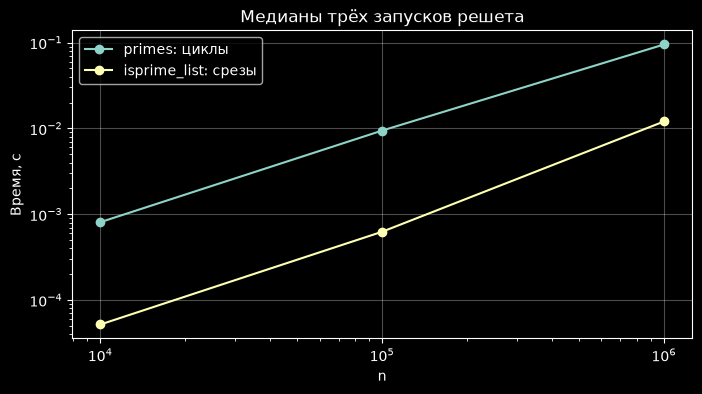

In [28]:
# Прогноз: срезы и исключение чётных кратных ускорят вторую реализацию.
sieve_timings=[]
for n in (10**4,10**5,10**6):
    assert primes(n)==where(isprime_list(n))
    row=[]
    for func in (primes,isprime_list):
        times=[]
        for _ in range(3):
            start=perf_counter(); result=func(n); times.append(perf_counter()-start)
        row.append(median(times))
    sieve_timings.append((n,*row))
    print('n, медианы primes / isprime_list, с:',n,*row)
fig,ax=plt.subplots(figsize=(8,4))
for j,label in ((1,'primes: циклы'),(2,'isprime_list: срезы')):
    ax.loglog([r[0] for r in sieve_timings],[r[j] for r in sieve_timings],'o-',label=label)
ax.set(xlabel='n',ylabel='Время, с',title='Медианы трёх запусков решета')
ax.grid(alpha=.3); ax.legend(); plt.show()

**Интерпретация.** Оба алгоритма используют решето и начинают отметки с $p^2$. Первая версия отмечает кратные по одному в Python, вторая переносит присваивание срезу во внутренний цикл реализации Python и после обработки 2 пропускает чётные кандидаты и чётные кратные нечётных простых. Числа с несколькими простыми делителями могут отмечаться повторно в обеих версиях. При увеличении $n$ растут число отметок, память и время; константы зависят от представления и срезов. Сравниваются именно эти реализации, причём `primes` дополнительно создаёт список значений, а `isprime_list` возвращает флаги. Поэтому это сравнение полных вызовов с разными выходными форматами, а не универсальное утверждение о скорости всех решёт. Замеры ограничены $10^6$, чтобы не создавать большой список ссылок; дальнейшие эксперименты используют компактные флаги.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### Практика. Функция `prime_range`

После построения решета удобно получить ещё одну небольшую функцию, которая возвращает простые числа из заданного диапазона.

Реализуйте

```python
def prime_range(a, b):
    ...
```

со следующим контрактом:

- аргументы $a$ и $b$ — целые числа;
- функция возвращает список всех простых $p$, для которых
  $$
  a\leq p<b;
  $$
- если $a\geq b$, результатом является пустой список;
- значения $a<2$ должны обрабатываться корректно.

Используйте уже реализованное решето: для одного диапазона не нужно заново вызывать `is_prime_fast(k)` для каждого отдельного $k$.

Проверьте функцию:

1. на нескольких небольших диапазонах, для которых ответ легко получить вручную;
2. на граничных случаях;
3. независимо в SageMath с помощью `prime_range(a, b)`.

**Подумайте:** почему при перечислении большого числа простых в одном ограниченном диапазоне одно решето естественнее многократного независимого запуска проверки простоты?

</div>

In [29]:
def prime_range(a,b):
    """Целые a,b; все простые в полуинтервале [a,b)."""
    if a>=b or b<=2: return []
    flags=isprime_list(b-1)
    return [p for p in range(max(2,a),b) if flags[p]]
for a,b,expected in [(-10,3,[2]),(2,2,[]),(10,2,[]),(2,3,[2]),(3,7,[3,5]),(10,20,[11,13,17,19]),(-5,-1,[])]:
    assert prime_range(a,b)==expected
    print((a,b),expected)

(-10, 3) [2]
(2, 2) []
(10, 2) []
(2, 3) [2]
(3, 7) [3, 5]
(10, 20) [11, 13, 17, 19]
(-5, -1) []


**Ответ.** Одно решето совместно исключает кратные, вместо независимых пробных делений каждого кандидата; при плотном перечислении ограниченного диапазона это экономит повторную работу. Для очень узкого диапазона с большой левой границей эффективнее сегментированное решето, но здесь используется уже изученный вариант. Верхняя граница $b$ не включается: например, `prime_range(3,7)` возвращает 3 и 5. Блок независимой сверки с SageMath находится в конце ноутбука.

# 5. Анализ данных

Теперь, когда мы научились быстро генерировать список простых чисел, мы можем заняться анализом данных: экспериментальной теорией чисел, чтобы найти тенденции и закономерности в последовательности простых чисел. Со времён Евклида (около 300 г. до н.э.) нам известно, что простых чисел бесконечно много. Но как они распределены? Какая доля чисел является простой и как меняется эта доля на разных числовых промежутках?

Как теоретические вопросы, эти проблемы относятся к области аналитической теории чисел. Однако трудно понять, что именно нужно доказывать, не проведя предварительных экспериментов. И поэтому, по крайней мере, с тех пор, как Гаусс начал изучать свои обширные таблицы простых чисел, математики активно занимаются экспериментальной теорией чисел.

## 5.1 Анализ списка простых чисел

Давайте начнем с создания нашего набора данных: простые числа до 1 миллиона.

In [30]:
prime_list = where(isprime_list(1000000))

In [31]:
len(prime_list) 

78498

In [32]:
prime_list[-1]  # Последнее простое число в нашем списке, перед миллионом.

999983

In [33]:
type(prime_list) # Какой тип этих данных

list

In [34]:
print(prime_list[:100]) # Первые сто простых чисел.

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 277, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541]


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 8
Выбрать из списка `prime_list` простые числа, которые можно представить в форме $4k+1$. Сохранить их в списке `redprimes`. Выбрать из списка `prime_list` простые числа, которые можно представить в форме $4k+3$. Сохранить их в списке `blueprimes`. Сколько простых чисел в этих списках? Проверьте, что сумма их длин равна `len(prime_list) - 1`, и объясните, какое простое число не попало ни в один список.

</div>


In [35]:
redprimes=[p for p in prime_list if p%4==1]
blueprimes=[p for p in prime_list if p%4==3]
assert len(redprimes)+len(blueprimes)==len(prime_list)-1
assert set(prime_list)-set(redprimes)-set(blueprimes)=={2}
print('4k+1:',len(redprimes),'4k+3:',len(blueprimes),'разность:',len(blueprimes)-len(redprimes))

4k+1: 39175 4k+3: 39322 разность: 147


**Ответ 8.** Все простые больше 2 нечётны и принадлежат ровно одному из классов 1 и 3 по модулю 4. Единственное исключение — простое 2. Численности и их разность вычислены и сохранены в выводе.

Должны получиться близкие значения! Кажется, что простые числа равномерно распределены между этими двумя множествами. Остаток от деления на 4 простого числа будет либо 1, либо 3 примерно с одинаковой вероятностью. Доказано, что асимптотически соотношение между количеством элементов в этих двух множествах приближается к 1.

## 5.2 Функция распределения простых чисел

Функция распределения простых чисел
$\pi(x)$ задаёт количество простых чисел, не превосходящих $x$.
Например, $\pi(2)=1$, $\pi(3)=2$, $\pi(4)=2$ и $\pi(5)=3$.

Дадим более формальное определение.

### Определение 5.1. Функция распределения простых чисел

Для $x>0$ **функцией распределения простых чисел** (*prime-counting function*) называется функция

$$
\pi(x)=\sum_{p\leq x}1.
$$

Изучение асимптотического поведения функции $\pi(x)$ является одной из важных задач аналитической теории чисел.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 9

Напишите функцию `prime_count(x)`, которая вычисляет $\pi(x)$ — количество простых чисел, не превосходящих $x$.

Используйте уже построенный упорядоченный список `prime_list`, а не запускайте решето заново при каждом вызове функции. Для поиска позиции $x$ в упорядоченном списке можно воспользоваться `bisect_right` из модуля `bisect`.

Проверьте функцию на малых значениях и найдите $\pi(1000)$.

</div>


In [36]:
from bisect import bisect_right
PRIME_TABLE_LIMIT=10**6
def prime_count(x):
    """Число простых <=x по готовой таблице; x<=10**6, иначе ValueError."""
    if x>PRIME_TABLE_LIMIT: raise ValueError('Запрос за пределами таблицы простых')
    return bisect_right(prime_list,x)
for x,expected in [(-3,0),(0,0),(1,0),(2,1),(3,2),(10,4),(100,25),(1000,168),(10**6,78498)]:
    assert prime_count(x)==expected
    print(x,prime_count(x))

-3 0
0 0
1 0
2 1
3 2
10 4
100 25
1000 168
1000000 78498


**Ответ 9.** $\pi(1000)=168$. `bisect_right` находит число элементов $\le x$ за $O(\log\pi(10^6))$ сравнений без повторного решета. Область таблицы явно ограничена $10^6$; последний найденный простой меньше этой границы, но это не означает, что запросы между ним и $10^6$ недопустимы. Запросы выше границы отклоняются, чтобы не выдавать неверный постоянный результат.

# 6. Анализ функции распределения простых чисел


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 10

Используя `prime_count(x)`, постройте график функции $\pi(x)$ для $1\leq x\leq 10^6$.

Не требуется вычислять $\pi(x)$ для каждого целого $x$: выберите разумную равномерную сетку значений, например с шагом $10^3$. Укажите использованный шаг.

</div>


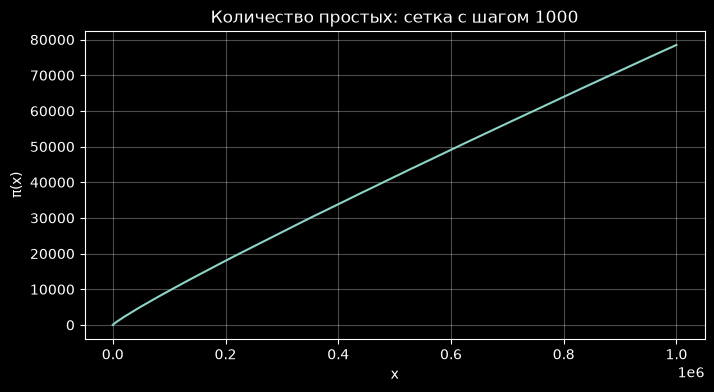

In [37]:
x_grid=np.concatenate(([1],np.arange(1000,10**6+1,1000)))
pi_grid=np.array([prime_count(int(x)) for x in x_grid])
def graph(x,y,title,ylabel,label=None,reference=None):
    fig,ax=plt.subplots(figsize=(8,4))
    ax.plot(x,y,label=label)
    if reference is not None: ax.axhline(reference,color='orange',linestyle='--',label=str(reference))
    ax.set(xlabel='x',ylabel=ylabel,title=title); ax.grid(alpha=.3)
    if label is not None or reference is not None: ax.legend()
    plt.show()
graph(x_grid,pi_grid,'Количество простых: сетка с шагом 1000','π(x)')

**Ответ 10.** Сетка состоит из точки 1 и точек 1000, 2000, …, 1 000 000. Между узлами проведены отрезки; сама функция π(x) ступенчатая. Значения определяются готовым списком, а не повторным решетом.

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

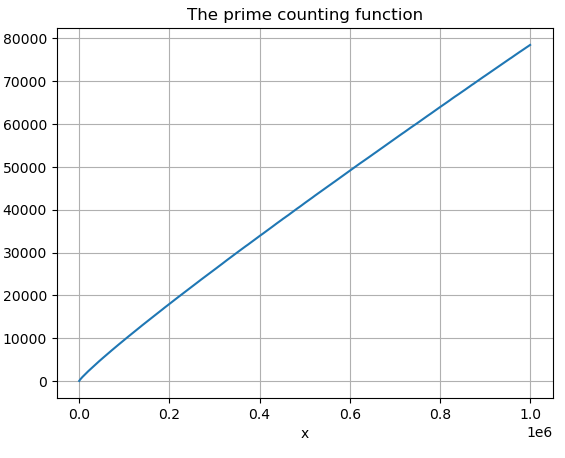
На первый взгляд можно сказать, что график носит линейный характер. Т.е. это линия вида $\pi(x)=mx$. Тогда, если нарисовать график функции $\pi(x)/x$, то мы увидим константу.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 11

Постройте график функции $\pi(x)/x$. По полученному результату сделайте вывод, является ли функция $\pi(x)$ линейной или нелинейной.

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

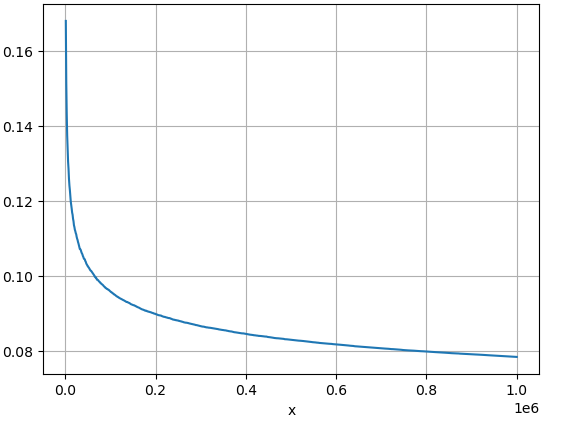

</div>


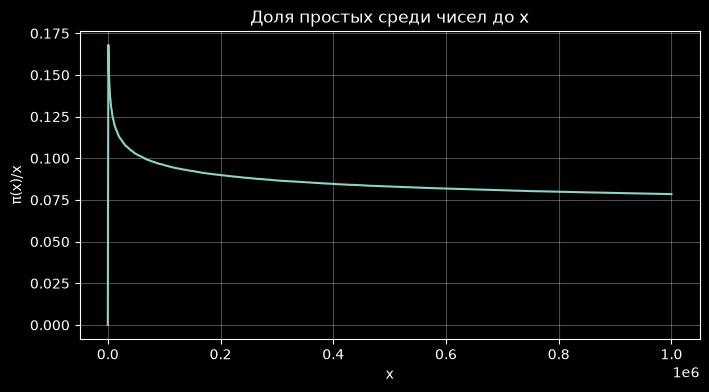

Доли при 1000, 10000, 100000, 1000000: [(1000, 0.168), (10000, 0.1229), (100000, 0.09592), (1000000, 0.078498)]


In [38]:
graph(x_grid,pi_grid/x_grid,'Доля простых среди чисел до x','π(x)/x')
print('Доли при 1000, 10000, 100000, 1000000:',[(x,prime_count(x)/x) for x in (1000,10000,100000,1000000)])

**Ответ 11.** Отношение не постоянно: на указанных степенях 10 оно уменьшается. Значит, $\pi(x)$ не является линейной функцией $mx$. Кроме того, точная $\pi(x)$ ступенчатая, а её средняя плотность по теореме о простых числах стремится к нулю как $1/\ln x$. Вид почти прямой линии на первом графике объясняется масштабом осей.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Смещение Чебышёва


Теорема Дирихле утверждает, что в каждом допустимом классе вычетов бесконечно много простых чисел. Её количественное уточнение — теорема о простых числах в арифметических прогрессиях (Ш.-Ж. де ла Валле Пуссен, 1896): простые числа асимптотически равномерно распределяются между допустимыми классами вычетов. В частности, для классов $1$ и $3$ по модулю $4$:

$$
\pi(x;4,1)\sim\pi(x;4,3)\sim\frac12\operatorname{li}(x).
$$

Здесь $\pi(x;4,a)$ — число простых $p\le x$ с $p\equiv a\pmod 4$, а $\operatorname{li}(x)=\int_2^x\frac{dt}{\ln t}$ — интегральный логарифм; подробно он появится в разделе 7.

Поэтому в пределе ни один из этих двух классов не получает положительной доли преимущества над другим.

Однако асимптотическое равенство не означает, что при конечных $x$ разность

$$
\pi(x;4,3)-\pi(x;4,1)
$$

должна одинаково часто принимать положительные и отрицательные значения. Вычисления обнаруживают устойчивую тенденцию: простые числа $p\equiv3\pmod4$ значительно чаще оказываются впереди простых $p\equiv1\pmod4$.

Это явление называется **смещением Чебышёва** (*Chebyshev's bias*). Следующее исследование предлагает сначала обнаружить его экспериментально, а затем отделить наблюдаемое конечное поведение от асимптотического утверждения о равномерном распределении простых по классам вычетов.

Для простых чисел $p>2$ рассмотрим два класса остатков по модулю 4:

$$
p\equiv1\pmod4
\qquad\text{и}\qquad
p\equiv3\pmod4.
$$

Определите функции

$$
\pi_1(x)=\#\{p\leq x:\;p\equiv1\pmod4\},
$$

$$
\pi_3(x)=\#\{p\leq x:\;p\equiv3\pmod4\}.
$$

Вычислите их для набора значений $x$ и постройте график разности

$$
\pi_3(x)-\pi_1(x).
$$

Дополнительно можно построить отношение $\pi_3(x)/\pi_1(x)$.

Исследуйте, наблюдается ли на выбранном диапазоне систематическое преобладание одного из классов.
При интерпретации результата учитывайте, что численный эксперимент на конечном диапазоне сам по себе не доказывает утверждение для всех $x$.

**Для дальнейшего чтения.** Наблюдаемое явление называется **смещением Чебышёва**
(*Chebyshev's bias*) и является частным случаем так называемых **гонок простых чисел**
(*prime number races*). Доступное введение с численными примерами и обсуждением
математической природы эффекта см.:

A. Granville, G. Martin. *Prime Number Races* // The American Mathematical Monthly.
2006. Vol. 113, No. 1. P. 1–33.

Более глубокое исследование:

M. Rubinstein, P. Sarnak. *Chebyshev's Bias* // Experimental Mathematics.
1994. Vol. 3, No. 3. P. 173–197.


</div>


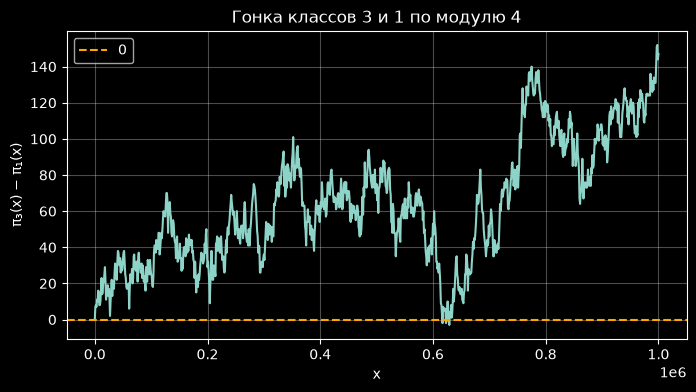

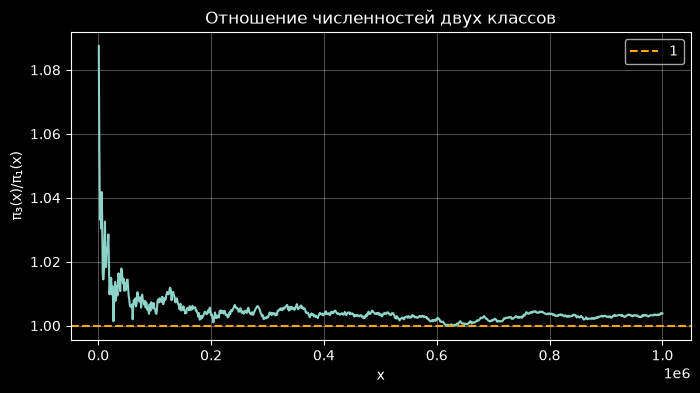

Доля узлов сетки с преимуществом класса 3: 0.995
Число узлов: класс 3 впереди / равны / класс 1 впереди: 995 1 4
При миллионе: 39175 39322 147


In [39]:
pi1=np.array([bisect_right(redprimes,int(x)) for x in x_grid])
pi3=np.array([bisect_right(blueprimes,int(x)) for x in x_grid])
delta=pi3-pi1
graph(x_grid,delta,'Гонка классов 3 и 1 по модулю 4','π₃(x) − π₁(x)',reference=0)
mask=pi1>0
graph(x_grid[mask],pi3[mask]/pi1[mask],'Отношение численностей двух классов','π₃(x)/π₁(x)',reference=1)
valid=x_grid>=3
print('Доля узлов сетки с преимуществом класса 3:',float(np.mean(delta[valid]>0)))
print('Число узлов: класс 3 впереди / равны / класс 1 впереди:',int(sum(delta[valid]>0)),int(sum(delta[valid]==0)),int(sum(delta[valid]<0)))
print('При миллионе:',pi1[-1],pi3[-1],delta[-1])

**Ответ исследования.** На выбранной равномерной сетке класс $3\pmod4$ чаще имеет преимущество; точная доля узлов и численности сохранены выше. Это доля именно узлов данной сетки, а не всех вещественных $x$ и не логарифмическая плотность. Асимптотическое равенство классов означает, что относительное преимущество исчезает, но не требует равного числа положительных и отрицательных значений разности на каждом конечном диапазоне. Эксперимент иллюстрирует смещение Чебышёва, не доказывая его для всех $x$.

# 7. Асимптотический закон распределения простых чисел

Асимптотический закон распределения простых чисел имеет вид

$$
\pi(x)\sim\frac{x}{\ln x},\qquad x\to\infty.
$$

Это означает, что отношение $\pi(x)$ к $x/\ln x$ стремится к 1 при $x\to\infty$.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 12
Наложите на график функции $\pi(x) / x$ график функции $1 / \ln(x)$.  
Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

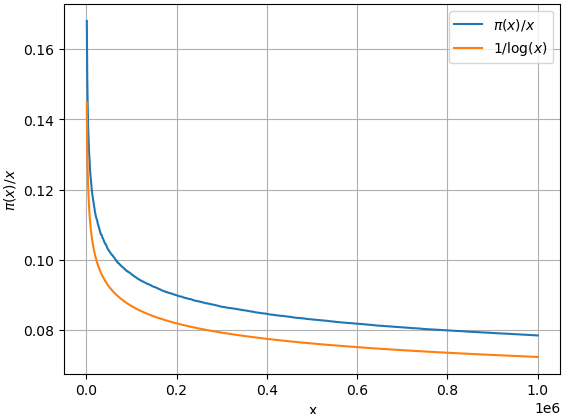

</div>


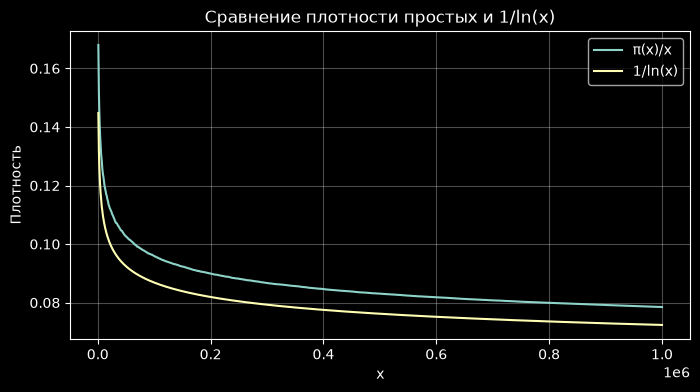

In [40]:
positive=x_grid>1
x_asym=x_grid[positive].astype(float); pi_asym=pi_grid[positive]
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(x_asym,pi_asym/x_asym,label='π(x)/x')
ax.plot(x_asym,1/np.log(x_asym),label='1/ln(x)')
ax.set(xlabel='x',ylabel='Плотность',title='Сравнение плотности простых и 1/ln(x)')
ax.grid(alpha=.3); ax.legend(); plt.show()

**Ответ 12.** На выбранных узлах кривые близки и в целом сближаются по масштабу. Точка $x=1$ исключена, поскольку $\ln1=0$. Приближение $1/\ln x$ описывает асимптотическую плотность, а не точную вероятность каждого отдельного целого числа.

Асимптотический закон распределения простых чисел известен как теорема о распределении простых чисел (**prime number theorem**):
$$\lim_{x \rightarrow \infty} \frac{\pi(x)}{x / \ln(x)} = 1.$$

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 13
Постройте график функции $$\frac{\pi(x)}{x / \ln(x)}.$$  
Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

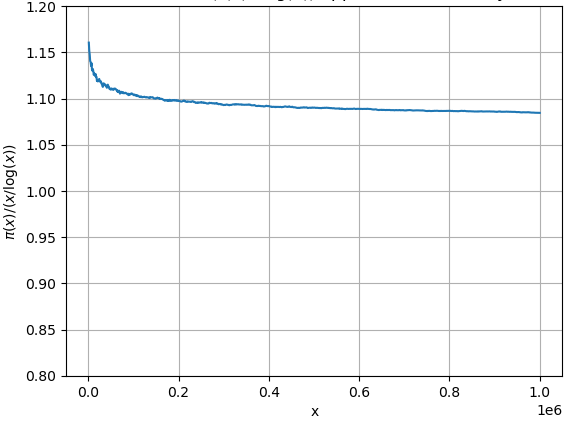

</div>


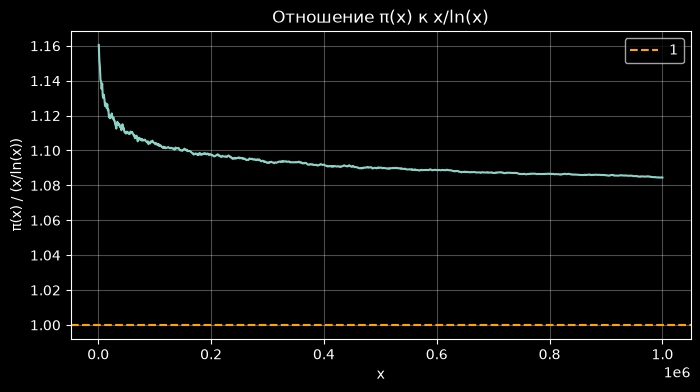

На правой границе: 1.0844899477790795


In [41]:
ratio_log=pi_asym/(x_asym/np.log(x_asym))
graph(x_asym,ratio_log,'Отношение π(x) к x/ln(x)','π(x) / (x/ln(x))',reference=1)
print('На правой границе:',ratio_log[-1])

**Ответ 13.** Отношение колеблется и на больших узлах рассматриваемой сетки становится ближе к 1. Это согласуется с $\pi(x)\sim x/\ln x$, но конечный график не доказывает предел и не означает монотонной сходимости.

Видно, что есть сходимость к 1, но очень медленная.

>Существует асимптотический закон распределения в следующей форме:  
$$\pi(x)\sim \operatorname{li}(x), x\to\infty,$$
где
$$\operatorname{li}(x) = \int_{2}^{x} \frac{dt}{\ln t}$$ - интегральный логарифм.

**Замечание о вычислении.** В пакете `mpmath` функция `li(x)` по умолчанию считает интеграл от $0$ (в смысле главного значения), который больше на $\int_0^2\frac{dt}{\ln t}\approx1{,}045$. Интеграл от $2$, как в нашем определении, даёт `li(x, offset=True)`. Для отношений $\pi(x)/\operatorname{li}(x)$ разница несущественна, но в таблицах значений её нужно учитывать.


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 14

Постройте график функции

$$
\frac{\pi(x)}{\operatorname{li}(x)}.
$$

Интегральный логарифм не входит в стандартную библиотеку Python и `numpy`, но функция `li` доступна в пакете `mpmath`:

```python
from mpmath import li

li(x, offset=True)   # интеграл от 2 — как в нашем определении
```

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

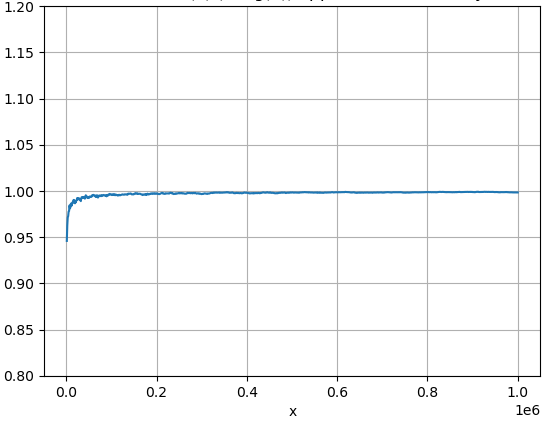

</div>


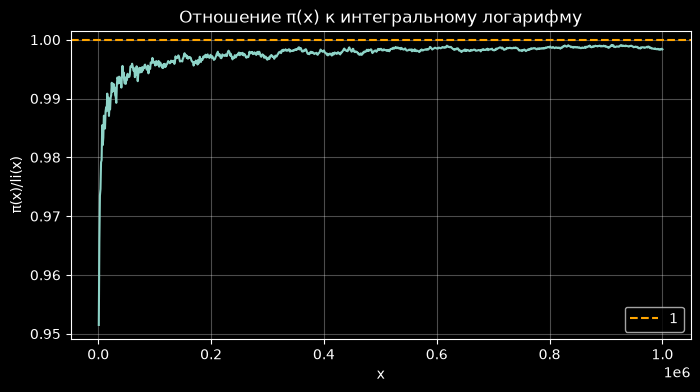

При миллионе: li = 78626.5039956820644270780661591 отношение = 0.9983656402211508


In [42]:
from mpmath import li, mp
mp.dps=30
li_grid=np.array([float(li(int(x),offset=True)) for x in x_asym])
assert np.all(li_grid>0)
graph(x_asym,pi_asym/li_grid,'Отношение π(x) к интегральному логарифму','π(x)/li(x)',reference=1)
print('При миллионе: li =',li(10**6,offset=True),'отношение =',pi_asym[-1]/li_grid[-1])

**Ответ 14.** Использован именно интеграл от 2 (`offset=True`). Отношение на выбранном диапазоне ближе к 1, чем для $x/\ln x$, особенно на правой границе. При $x=2$ этот интеграл равен нулю, поэтому точка 2 также не подходит для такого отношения; наша сетка для сравнений начинается с 1000.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 15

Гипотеза Римана равносильна оценке (Х. фон Кох, 1901)

$$
\left|\pi(x)-\operatorname{li}(x)\right|
=O\!\left(\sqrt{x}\,\ln x\right).
$$

Численно исследуйте величину

$$
\frac{\left|\pi(x)-\operatorname{li}(x)\right|}
{\sqrt{x}\,\ln x}
$$

на рассматриваемом диапазоне значений $x$. Постройте график этой величины и опишите наблюдаемое поведение.

**Важно:** численный эксперимент на конечном диапазоне не является доказательством приведённой асимптотической оценки или гипотезы Римана.

</div>


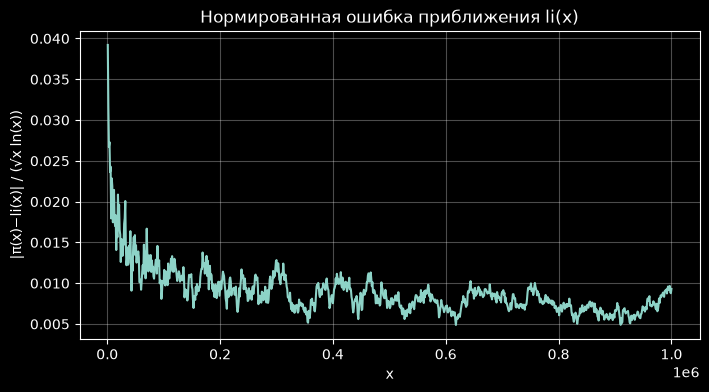

Минимум / максимум / значение справа: 0.0048825139367700355 0.03920710508294814 0.009301429371206994


In [43]:
rh_scaled=np.abs(pi_asym-li_grid)/(np.sqrt(x_asym)*np.log(x_asym))
graph(x_asym,rh_scaled,'Нормированная ошибка приближения li(x)','|π(x)−li(x)| / (√x ln(x))')
print('Минимум / максимум / значение справа:',float(min(rh_scaled)),float(max(rh_scaled)),float(rh_scaled[-1]))

**Ответ 15.** На этой сетке нормированная ошибка мала, колеблется и не показывает неограниченного роста; диапазон значений выведен программой. Деление на $\sqrt x\ln x$ позволяет сравнивать ошибку с масштабом оценки в задании. Ограниченность конечного набора значений тривиальна и не устанавливает существование единой константы для всех достаточно больших $x$; гипотеза Римана этим не доказана.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 16

Найдите относительную погрешность приближения

$$
\pi(x)\approx\operatorname{li}(x)
$$

для значений

$$
x=10^6,\;10^7,\;10^8,\;10^9.
$$

Используйте относительную погрешность

$$
\varepsilon(x)=
\frac{\left|\operatorname{li}(x)-\pi(x)\right|}{\pi(x)}.
$$

Для $x>10^6$ **не создавайте** список `flags` (тип `list`) длиной $x+1$: такая реализация решета в Python расходует слишком много памяти (8 байт на ссылку, около 8 ГБ при $x=10^9$).

Точные значения $\pi(x)$ можно получить независимо в **SageMath** с помощью функции

```python
prime_pi(x)
```

Если SageMath не установлен локально, воспользуйтесь онлайн-средой [SageMathCell](https://sagecell.sagemath.org/). Например:

```python
prime_pi(10^9)
```

Значение $\operatorname{li}(x)$ вычислите в Python с помощью `mpmath.li(x, offset=True)` — это интеграл от $2$, как в определении раздела 7.

Для ориентира рассмотрим два примера сравнения $\pi(x)$ с приближениями $x/\ln x$ и $\operatorname{li}(x)$:

| $x$ | $\pi(x)$ | $x/\ln x$ | Относительная погрешность | $\operatorname{li}(x)$ | Относительная погрешность |
| ---: | ---: | ---: | ---: | ---: | ---: |
| $10^3$ | $168$ | $145$ | $\approx 13.8\%$ | $177$ | $\approx 5.1\%$ |
| $10^6$ | $78\,498$ | $72\,382$ | $\approx 7.8\%$ | $78\,627$ | $\approx 0.16\%$ |

В таблице $\operatorname{li}(x)=\int_2^x dt/\ln t$ (`offset=True`); погрешности вычислены по неокруглённым значениям.

Вычислите $\varepsilon(x)$ для всех указанных в задании значений $x$ и сравните полученные результаты.

**Сделайте вывод:** как изменяется относительная погрешность приближения $\operatorname{li}(x)$ при росте $x$? Что показывают результаты эксперимента о качестве приближения $\pi(x)\approx\operatorname{li}(x)$ на рассматриваемом диапазоне?

</div>

In [44]:
def prime_pi_exact(n):
    """Точный комбинаторный подсчёт π(n) с O(sqrt(n)) хранимых значений."""
    if n<2: return 0
    r=math.isqrt(n)
    values=sorted(set(range(1,r+1)) | {n//i for i in range(1,r+1)},reverse=True)
    counts={v:v-1 for v in values}
    for p in range(2,r+1):
        if counts[p]==counts[p-1]: continue
        smaller=counts[p-1]
        square=p*p
        for v in values:
            if v<square: break
            counts[v]-=counts[v//p]-smaller
    return counts[n]

for n in range(0,301):
    assert prime_pi_exact(n)==prime_count(n)
relative_errors=[]
print('x | π(x) точно | li(x) | относительная ошибка | процент | время подсчёта, с')
for x in (10**6,10**7,10**8,10**9):
    start=perf_counter(); exact=prime_pi_exact(x); elapsed=perf_counter()-start
    approximation=li(x,offset=True)
    error=abs(approximation-exact)/exact
    relative_errors.append((x,exact,float(approximation),float(error)))
    print(x,exact,mp.nstr(approximation,15),mp.nstr(error,10),mp.nstr(100*error,8),elapsed)
assert [r[1] for r in relative_errors]==[78498,664579,5761455,50847534]

x | π(x) точно | li(x) | относительная ошибка | процент | время подсчёта, с
1000000 78498 78626.5039956821 0.001637035283 0.16370353 0.002516399952583015
10000000 664579 664917.359884789 0.0005091341809 0.050913418 0.01280849997419864
100000000 5761455 5762208.33028425 0.0001307534788 0.013075348 0.07071639993228018


1000000000 50847534 50849233.911838 3.343154927e-5 0.0033431549 0.3863497000420466


**Ответ 16 и точность подсчёта.** Точные значения $\pi(x)$ получены собственным независимым комбинаторным решетом счётчиков, а не приближением и не массивом длины $10^9$. Хранятся только значения $v\le\sqrt n$ и $\lfloor n/i\rfloor$, их $O(\sqrt n)$. Начальный счётчик $S(v)=v-1$ считает числа 2,…,$v$. На шаге простого $p$ удаляются числа с наименьшим простым делителем $p$: $S(v)\gets S(v)-[S(\lfloor v/p\rfloor)-S(p-1)]$ при $v\ge p^2$. Значения обходятся по убыванию, чтобы использовать счётчики до текущего шага. После последнего $p\le\sqrt n$ остаются ровно простые. Это отдельный учебный алгоритм для эксперимента, не замена функции `prime_count` из задания 9.

Таблица содержит неокруглённые для расчёта значения `li` и ошибки. На выбранных степенях 10 относительная погрешность уменьшается; это показывает улучшение приближения на данных точках, но не доказывает монотонности ошибки при каждом увеличении $x$. SageMath здесь не имитируется: независимый блок для соответствующего ядра приведён отдельно.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Почему это важно?** В SageMath уже есть функция `next_prime(n)`, которая возвращает наименьшее простое число, строго большее $n$. Построим её учебный аналог на основе уже реализованной проверки простоты. Это свяжет алгоритм поиска простых чисел со следующим разделом о промежутках между простыми.

</div>

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 17

Реализуйте функцию

```python
def next_prime(n):
    ...
```

которая для целого $n$ возвращает **наименьшее простое число $p>n$**.

1. Сформулируйте контракт функции и отдельно проверьте случаи $n<2$, $n=2$ и чётные значения $n$.
2. После обработки числа $2$ не перебирайте чётные кандидаты: объясните, почему достаточно переходить от одного нечётного кандидата к следующему с шагом $2$.
3. Для проверки простоты кандидата используйте ранее реализованную `is_prime_fast`.
4. Проверьте функцию на нескольких небольших значениях, для которых ответ легко установить вручную.
5. Выполните независимую проверку результатов в SageMath с помощью `next_prime(n)` (или метода `ZZ(n).next_prime()`).
6. Для нескольких значений $n$ вычислите величину
   $$
   d(n)=\operatorname{next\_prime}(n)-n.
   $$
   Что измеряет $d(n)$? В каком случае эта величина является промежутком между двумя последовательными простыми числами?

**Важно.** Это учебная реализация. Её эффективность определяется используемым тестом простоты. Позже мы заменим перебор делителей вероятностным тестом простоты, пригодным для существенно больших чисел.

</div>

In [45]:
def next_prime(n):
    """Для целого n возвращает наименьшее простое строго больше n."""
    if n<2: return 2
    candidate=n+1
    if candidate%2==0: candidate+=1
    while not is_prime_fast(candidate): candidate+=2
    return candidate
for n,expected in [(-10,2),(0,2),(1,2),(2,3),(3,5),(4,5),(10,11),(11,13),(100,101)]:
    assert next_prime(n)==expected
    print(n,'->',expected,'d(n) =',expected-n)
for n in range(-5,1001):
    p=next_prime(n)
    assert p>n and is_prime_fast(p)
    assert not any(is_prime_fast(k) for k in range(max(2,n+1),p))

-10 -> 2 d(n) = 12
0 -> 2 d(n) = 2
1 -> 2 d(n) = 1
2 -> 3 d(n) = 1
3 -> 5 d(n) = 2
4 -> 5 d(n) = 1
10 -> 11 d(n) = 1
11 -> 13 d(n) = 2
100 -> 101 d(n) = 1


**Ответ 17.** После отдельного случая 2 все простые нечётны, поэтому шаг 2 не пропускает допустимый ответ. Перебор по возрастанию и остановка на первом простом гарантируют минимальность; существование следующего простого следует из бесконечности простых. $d(n)$ — расстояние от входного целого до ближайшего простого строго справа. Оно является промежутком между соседними простыми именно тогда, когда само $n$ простое.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### Challenge. Функция `previous_prime`

Постройте симметричную к `next_prime` функцию

```python
def previous_prime(n):
    ...
```

которая возвращает **наибольшее простое число $p<n$**.

1. Сформулируйте контракт функции.
2. Определите, что должна делать функция при $n\leq2$: возвращать специальное значение или возбуждать исключение. Обоснуйте выбранный контракт.
3. После обработки числа $2$ используйте только нечётные кандидаты.
4. Переиспользуйте ранее реализованную `is_prime_fast`, а не дублируйте код проверки простоты.
5. Проверьте несколько значений вручную и независимо в SageMath с помощью `previous_prime(n)` или `ZZ(n).previous_prime()`.
6. Сравните структуры `next_prime` и `previous_prime`: какие части алгоритма совпадают, а где появляются различные граничные случаи?

</div>

In [46]:
def previous_prime(n):
    """Целое n>2; наибольшее простое строго меньше n. При n<=2 ValueError."""
    if n<=2: raise ValueError('Простого числа строго меньше n не существует')
    if n<=3: return 2
    candidate=n-1
    if candidate%2==0: candidate-=1
    while candidate>=3:
        if is_prime_fast(candidate): return candidate
        candidate-=2
    return 2
for n,expected in [(3,2),(4,3),(5,3),(10,7),(11,7),(100,97)]:
    assert previous_prime(n)==expected
    print(n,'->',expected)
for n in (-10,0,1,2):
    try: previous_prime(n)
    except ValueError: pass
    else: raise AssertionError('Ожидалось исключение')
for n in range(3,1001):
    p=previous_prime(n)
    assert p<n and is_prime_fast(p)
    assert not any(is_prime_fast(k) for k in range(p+1,n))

3 -> 2
4 -> 3
5 -> 3
10 -> 7
11 -> 7
100 -> 97


**Ответ Challenge.** При n≤2 подходящего простого не существует, поэтому выбрано явное исключение, а не несуществующий числовой ответ. Оба поиска переиспользуют `is_prime_fast` и обходят нечётные кандидаты с шагом 2. Различаются направление обхода и границы: справа ответ всегда существует, слева нужно обрабатывать отсутствие ответа и отдельно возвращать 2. Независимая сверка SageMath вынесена в общий блок.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Наш API и SageMath.** К этому моменту у нас появились собственные учебные реализации нескольких стандартных операций с простыми числами. SageMath удобно использовать как **независимый инструмент проверки**, но не как замену выводу алгоритма, доказательству корректности и анализу сложности.

| Наша учебная функция | SageMath | Что сравниваем |
| --- | --- | --- |
| `is_prime_fast(n)` | `is_prime(n)` | простое ли число $n$ |
| `where(isprime_list(n))` | `prime_range(0, n + 1)` | все простые числа, не превосходящие $n$ |
| `prime_range(a, b)` | `prime_range(a, b)` | простые числа в полуинтервале $[a,b)$ |
| `prime_count(x)` | `prime_pi(x)` | значение функции $\pi(x)$ |
| `next_prime(n)` | `next_prime(n)` | ближайшее простое строго справа от $n$ |
| `previous_prime(n)` | `previous_prime(n)` | ближайшее простое строго слева от $n$ |

Если SageMath не установлен локально, небольшие проверки можно выполнять в [SageMathCell](https://sagecell.sagemath.org/).

Совпадение результатов двух независимых реализаций — полезный тест, но **не доказательство корректности**. Для учебной реализации по-прежнему нужно понимать математическую идею, контракт, граничные случаи и стоимость алгоритма.

</div>

# 8. Промежутки между простыми числами (prime gaps)

Изучение распределения промежутков между простыми числами является важной задачей теории чисел.
$n$-й промежуток между последовательными простыми числами определяется как

$$
g_n=p_{n+1}-p_n.
$$

Начало последовательности промежутков:
$(3-2=1), (5-3=2), (7-5=2), (11-7=4), (13-11=2), (17-13=4),\ldots$

Несколько простых наблюдений:

- $g_n$ всегда чётен при $p_n>2$, поскольку все простые числа больше 2 нечётны;
- $g_n\geq2$ для всех $n>1$;
- $g_n=2$ для пар простых-близнецов, например $(3,5)$, $(5,7)$, $(11,13)$.

## 8.1. Средний масштаб промежутка

В предыдущем разделе мы использовали асимптотический закон распределения простых чисел

$$
\pi(x)\sim\frac{x}{\ln x}.
$$

Среди чисел от $1$ до $x$ находится примерно $\pi(x)$ простых. Поэтому среднее расстояние между простыми на всём отрезке до $x$ имеет масштаб

$$
\frac{x}{\pi(x)}.
$$

Подставляя асимптотику для $\pi(x)$, получаем

$$
\frac{x}{\pi(x)}
\sim
\ln x.
$$

Таким образом, **средний масштаб промежутка между простыми числами около больших значений $x$ естественно сравнивать с $\ln x$**. Это объясняет, почему по мере роста $x$ простые числа в среднем встречаются реже.

Важно различать глобальную среднюю закономерность и конкретные локальные промежутки: отдельный $g_n$ может быть существенно меньше или существенно больше $\ln p_n$.

Для сравнения промежутков, возникающих при разных размерах чисел, удобно рассматривать **нормированный промежуток**

$$
\rho_n=\frac{g_n}{\ln p_n}.
$$

Величина $\rho_n$ показывает размер конкретного промежутка в единицах естественного среднего масштаба $\ln p_n$.


## 8.2. Сколь угодно большие промежутки

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Предложение 8.1. Существование сколь угодно длинных последовательностей составных чисел</strong>

Для любого натурального $m$ существуют $m$ последовательных составных чисел. Следовательно, промежутки между последовательными простыми числами не ограничены сверху.

</div>

**Доказательство.** Рассмотрим числа

$$
(m+1)!+2,\;(m+1)!+3,\;\ldots,\;(m+1)!+(m+1).
$$

Их ровно $m$. Для каждого целого $k$, где $2\leq k\leq m+1$, число $k$ делит $(m+1)!$. Поэтому

$$
k\mid\bigl((m+1)!+k\bigr).
$$

При этом $(m+1)!+k>k$, следовательно, $(m+1)!+k$ является составным. Мы получили $m$ последовательных составных чисел.

Так как $m$ можно выбрать сколь угодно большим, существуют сколь угодно длинные участки без простых чисел. Следовательно, последовательность промежутков $g_n$ не ограничена сверху. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Что произошло?** Асимптотика $\pi(x)\sim x/\ln x$ описывает среднюю плотность простых чисел, но не запрещает больших локальных отклонений. Факториальная конструкция явно создаёт длинный интервал, в котором простых чисел нет вообще.

</div>


## 8.3. Малые промежутки и современная картина

Противоположный вопрос — насколько часто простые числа могут находиться очень близко друг к другу.

Гипотеза о простых числах-близнецах утверждает, что существует бесконечно много пар простых чисел,
различающихся на $2$, то есть бесконечно много индексов $n$, для которых

$$
g_n=2.
$$

Эта гипотеза до сих пор не доказана.

В то же время современная теория даёт более слабый, но принципиально важный результат: существует некоторая абсолютная константа $B$, такая что для бесконечно многих $n$

$$
p_{n+1}-p_n\leq B.
$$

Иными словами, доказано существование **ограниченных промежутков между простыми числами** (*bounded gaps between primes*), хотя значение $B=2$, соответствующее гипотезе о простых-близнецах, пока недоступно.

В этом курсе мы не будем доказывать теоремы об ограниченных промежутках: их доказательства используют развитые методы аналитической теории чисел и решет. Для нас важнее вычислительно увидеть одновременно две особенности последовательности простых:

- абсолютные промежутки $g_n$ могут становиться очень большими;
- при сравнении промежутков на разных масштабах естественно учитывать нормировку $g_n/\ln p_n$.


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 18

Для простых чисел, не превосходящих $10^6$, вычислите промежутки

$$
g_n=p_{n+1}-p_n
$$

и постройте гистограмму их распределения.

Определите наиболее часто встречающийся размер промежутка. Если позволяет время вычислений, повторите эксперимент для $10^7$ и сравните распределения. Для $10^7$ и больше не используйте список `flags` типа `list` (см. задание 16): храните флаги в `bytearray` (1 байт на число) либо получите простые в SageMath через `prime_range`.

</div>


Граница: 1000000 простых: 78498 мода промежутка / частота: [(6, 13549)]
Частоты 2,4,6,12: [(2, 8169), (4, 8143), (6, 13549), (12, 8005)]


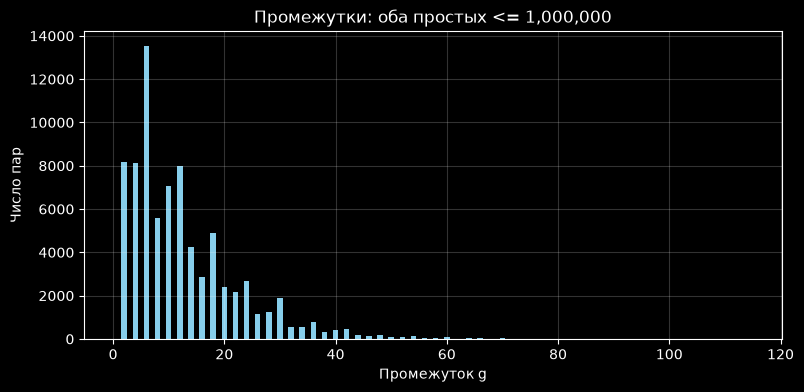

Граница: 10000000 простых: 664579 мода промежутка / частота: [(6, 99987)]
Частоты 2,4,6,12: [(2, 58980), (4, 58621), (6, 99987), (12, 65513)]


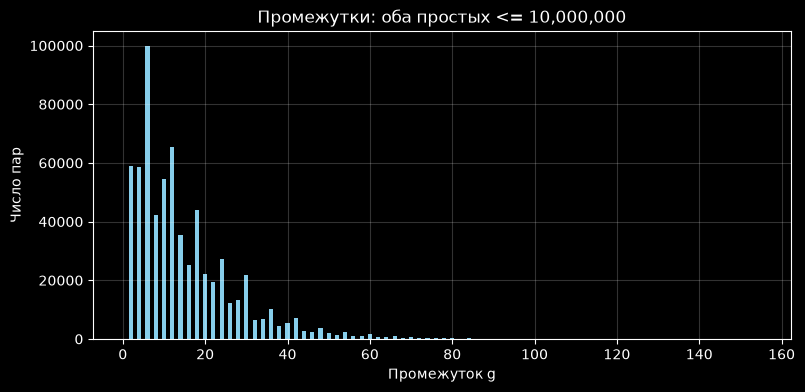

In [47]:
from collections import Counter
def isprime_bytes(n):
    """Компактное решето, один байт на индекс; граница n включена."""
    if n<0: raise ValueError('n должно быть неотрицательным')
    flags=bytearray(b'\x01')*(n+1)
    flags[0]=0
    if n>=1: flags[1]=0
    if n>=4: flags[4::2]=b'\x00'*((n-4)//2+1)
    for p in range(3,math.isqrt(n)+1,2):
        if flags[p]: flags[p*p::2*p]=b'\x00'*((n-p*p)//(2*p)+1)
    return flags
for n in (0,1,2,3,4,9,25,100,1000):
    assert list(map(bool,isprime_bytes(n)))==isprime_list(n)

gap_data={}
for limit in (10**6,10**7):
    flags=isprime_bytes(limit)
    ps=np.flatnonzero(np.frombuffer(flags,dtype=np.uint8))
    gaps=np.diff(ps)
    freq=Counter(map(int,gaps))
    gap_data[limit]=(ps,gaps,freq)
    assert len(ps)==prime_pi_exact(limit)
    print('Граница:',limit,'простых:',len(ps),'мода промежутка / частота:',freq.most_common(1))
    print('Частоты 2,4,6,12:',[(g,freq[g]) for g in (2,4,6,12)])
    fig,ax=plt.subplots(figsize=(9,4))
    bins=np.arange(.5,int(gaps.max())+1.5,1)
    ax.hist(gaps,bins=bins,color='skyblue')
    ax.set(xlabel='Промежуток g',ylabel='Число пар',title=f'Промежутки: оба простых <= {limit:,}')
    ax.grid(alpha=.2); plt.show()
del flags

**Ответ 18.** Гистограммы построены до $10^6$ и $10^7$ по всем соседним парам, оба конца которых не превосходят границу. Точные моды и частоты приведены в выводе; наиболее частый промежуток на обоих диапазонах — 6. Кроме пары (2,3), промежутки чётные. Относительные высоты пиков меняются с диапазоном; распределение не равномерно. Для большого диапазона использован `bytearray`, а индексы простых и промежутки хранятся в компактных массивах NumPy, без списка логических ссылок длины $10^7$.

Для диапазона до $10^6$ промежутки размера $2$ (простые-близнецы) встречаются более 8000 раз; близкое число раз встречается и промежуток размера $4$. Наиболее заметный пик возникает при размере $6$, а повышенные частоты наблюдаются также при значениях $12,18,24,30$.

Это наблюдение относится к конечному вычислительному диапазону и само по себе не является асимптотическим утверждением.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Абсолютные и нормированные промежутки между простыми числами

Для простых чисел, не превосходящих $10^6$, рассмотрите абсолютные промежутки

$$
g_n=p_{n+1}-p_n
$$

и нормированные промежутки

$$
\rho_n=\frac{g_n}{\ln p_n}.
$$

**Prediction.** До вычислений сформулируйте прогноз: будет ли пара простых, на которой достигается максимальный $g_n$, обязательно давать и максимальное значение $\rho_n$? Обоснуйте ответ.

**Run.**

1. Найдите максимальный абсолютный промежуток $g_n$ и пару последовательных простых чисел $(p_n,p_{n+1})$, между которыми он возникает.
2. Для этой пары вычислите $\rho_n=g_n/\ln p_n$.
3. Независимо найдите максимальное значение $\rho_n$ на том же диапазоне и соответствующую пару простых.
4. Постройте график $\rho_n$ как функции от $p_n$ или изобразите распределение значений $\rho_n$.
5. Повторите основные вычисления для $10^7$ и, если позволяет время вычислений и память, для $10^8$. Для $10^7$ и больше не используйте список `flags` типа `list` (см. задание 16): храните флаги в `bytearray` (1 байт на число) либо получите простые в SageMath через `prime_range`.

**Explain.** Сравните поведение $g_n$ и $\rho_n$. Объясните, зачем при сравнении промежутков, возникающих на существенно разных масштабах, делить $g_n$ на $\ln p_n$.

**Generalize.** Согласуются ли результаты с тем, что $\ln x$ задаёт средний масштаб промежутка около больших $x$? Почему конечный вычислительный эксперимент не доказывает утверждений об асимптотическом поведении максимальных или нормированных промежутков?

</div>


Граница / пара max g / max g / rho этой пары / пара max rho / max rho: (1000000, (492113, 492227), 114, 8.697998414931552, (370261, 370373), 8.735011647190985)


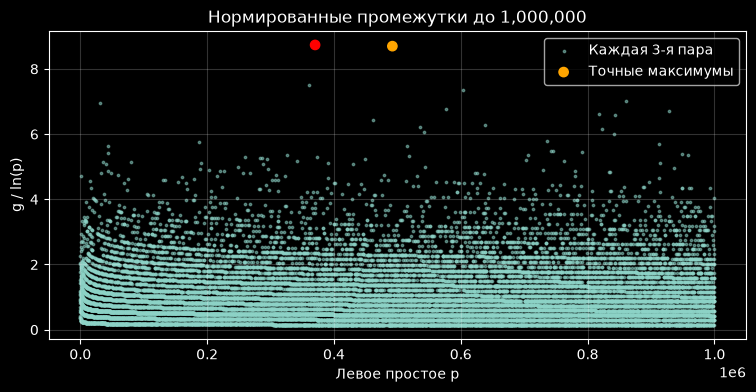

Граница / пара max g / max g / rho этой пары / пара max rho / max rho: (10000000, (4652353, 4652507), 154, 10.03068891155968, (2010733, 2010881), 10.197044174552891)


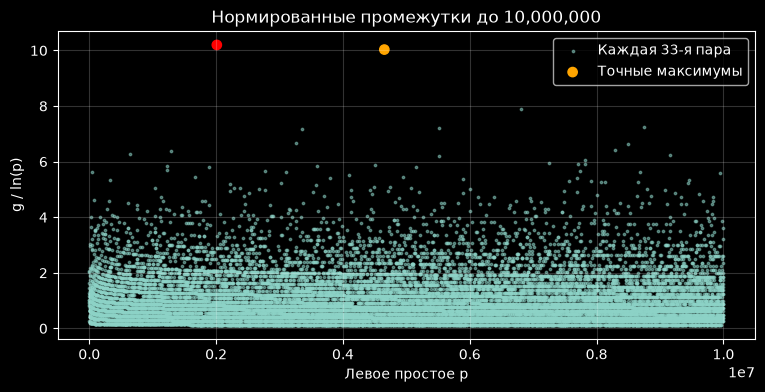

In [48]:
# Прогноз: максимум g и максимум g/ln(p) не обязаны возникать на одной паре.
gap_maxima=[]
for limit,(ps,gaps,freq) in gap_data.items():
    rho=gaps/np.log(ps[:-1])
    i=int(np.argmax(gaps)); j=int(np.argmax(rho))
    row=(limit,(int(ps[i]),int(ps[i+1])),int(gaps[i]),float(rho[i]),(int(ps[j]),int(ps[j+1])),float(rho[j]))
    gap_maxima.append(row)
    print('Граница / пара max g / max g / rho этой пары / пара max rho / max rho:',row)
    # Вычисление максимумов использует все пары; график отображает выборку.
    stride=max(1,len(rho)//20000)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.scatter(ps[:-1:stride],rho[::stride],s=3,alpha=.5,label=f'Каждая {stride}-я пара')
    ax.scatter([ps[i],ps[j]],[rho[i],rho[j]],color=['orange','red'],s=45,label='Точные максимумы')
    ax.set(xlabel='Левое простое p',ylabel='g / ln(p)',title=f'Нормированные промежутки до {limit:,}')
    ax.grid(alpha=.2); ax.legend(); plt.show()

**Прогноз и объяснение.** Максимум абсолютного промежутка не обязан максимизировать отношение: при разных левых концах меняется знаменатель $\ln p$. Поэтому более короткий ранний промежуток может быть большим относительно локального среднего масштаба. Для обоих диапазонов точные пары и значения вычислены по всем промежуткам; при совпадении нескольких максимумов выводится первая пара. График прорежен только для удобства отображения, не для поиска максимумов.

Нормировка показывает размер отклонения в единицах среднего масштаба, который растёт примерно как $\ln x$. Результаты согласуются с этим масштабом, но не устанавливают асимптотику максимальных промежутков. Средний масштаб не является верхней границей каждого промежутка. Эксперимент до $10^7$ выполнен; дополнительный диапазон $10^8$ не запускался, чтобы ограничить память и объём работы — он указан в условии как необязательный.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 19

**«Заговор простых чисел»** (Prime Conspiracy).

Рассмотрим пару последовательных простых чисел. Пусть первое оканчивается цифрой $a$, а следующее за ним — цифрой $b$.
Например, пара $(3,7)$ означает, что за простым числом, оканчивающимся на 3, следует простое число, оканчивающееся на 7.

Для достаточно больших простых чисел возможны последние цифры 1, 3, 7 и 9. Если бы переходы между последними цифрами
соседних простых чисел были независимыми и равновероятными, каждая из 16 возможных пар
$(1,1),(1,3),(1,7),(1,9),\ldots,(9,9)$ встречалась бы примерно в $1/16=6.25\%$ случаев.

Исследуйте фактическое распределение этих пар среди простых чисел, не превосходящих одного миллиона.
Сравните полученные частоты с $6.25\%$ и опишите наблюдаемое отклонение от равномерного распределения.

</div>


Всего учтённых соседних пар: 78494
Строка — последняя цифра первого, столбец — следующего: (1, 3, 7, 9)
1 4.0933% 8.0248% 8.3446% 4.5290%
3 5.5890% 3.5799% 7.4133% 8.4682%
7 6.4578% 6.9343% 3.6602% 7.9446%
9 8.8516% 6.5126% 5.5775% 4.0194%
Средняя частота диагональной пары: 3.838191454123882 %; эталон 6.25%


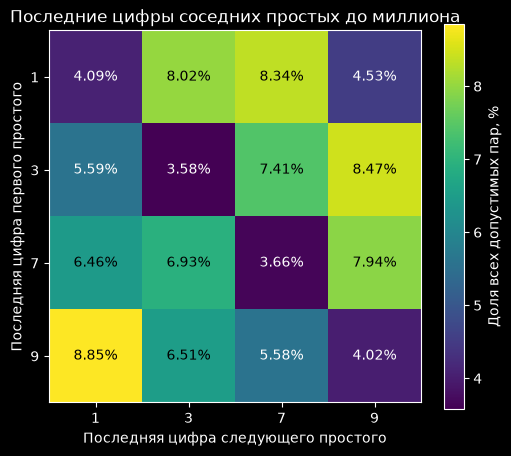

In [49]:
digits=(1,3,7,9)
transitions=Counter()
for p,q in zip(prime_list,prime_list[1:]):
    a,b=p%10,q%10
    if a in digits and b in digits: transitions[a,b]+=1
total=sum(transitions.values())
matrix=np.array([[100*transitions[a,b]/total for b in digits] for a in digits])
assert sum(transitions.values())==len(prime_list)-4
print('Всего учтённых соседних пар:',total)
print('Строка — последняя цифра первого, столбец — следующего:',digits)
for a,row in zip(digits,matrix): print(a,' '.join(f'{v:.4f}%' for v in row))
print('Средняя частота диагональной пары:',float(np.trace(matrix)/4),'%; эталон 6.25%')
fig,ax=plt.subplots(figsize=(6,5))
img=ax.imshow(matrix,cmap='viridis')
for i in range(4):
    for j in range(4): ax.text(j,i,f'{matrix[i,j]:.2f}%',ha='center',va='center',color='white' if matrix[i,j]<6 else 'black')
ax.set(xticks=range(4),yticks=range(4),xticklabels=digits,yticklabels=digits,xlabel='Последняя цифра следующего простого',ylabel='Последняя цифра первого простого',title='Последние цифры соседних простых до миллиона')
fig.colorbar(img,ax=ax,label='Доля всех допустимых пар, %'); plt.show()

**Ответ 19.** Пропущены только исходные соседние пары с участием 2 или 5: (2,3), (3,5), (5,7); простые предварительно не фильтровались, поэтому искусственных соседей (3,7) не создаётся. Для каждой из 16 пар частота делится на общее число допустимых переходов, а не на сумму строки; именно эти совместные частоты нужно сравнивать с 6.25%.

В таблице виден дефицит одинаковых последних цифр (диагональ) и предпочтение некоторых разных цифр. Значит, модель независимых равновероятных последних цифр плохо описывает соседние простые на этом диапазоне. Частоты конечной выборки не доказывают точной предельной величины или сохранения того же размера отклонения при росте границы.

### Итоговая проверка пакета, тестов и доступности SageMath


In [50]:
# Независимая проверка SageMath: выполняется только при наличии Sage.
try:
    from sage.all import is_prime as sage_is_prime, prime_range as sage_prime_range, prime_pi as sage_prime_pi, next_prime as sage_next, previous_prime as sage_previous
except ImportError:
    print('SageMath отсутствует: эта дополнительная сверка не выполнена. Результаты Sage не подставлялись.')
else:
    for n in range(-10,1001):
        assert is_prime_fast(n)==bool(sage_is_prime(n))
        assert next_prime(n)==int(sage_next(n))
        if n>2: assert previous_prime(n)==int(sage_previous(n))
    for a,b in [(-5,3),(2,3),(3,7),(10,100),(0,1001)]:
        assert prime_range(a,b)==list(map(int,sage_prime_range(max(0,a),max(0,b))))
    for x,exact,_,_ in relative_errors:
        assert exact==int(sage_prime_pi(x))
    print('Независимая сверка SageMath выполнена.')

import subprocess, json
from importlib import metadata
import sysconfig
dist=next(d for d in metadata.distributions(path=[sysconfig.get_path('purelib')]) if d.metadata['Name']=='crypto-math-course')
direct=json.loads(dist.read_text('direct_url.json'))
assert direct.get('dir_info',{}).get('editable') is True
print('Editable-установка:',direct)
print('Пакет импортирован из:',crypto_math.__file__)
result=subprocess.run([sys.executable,'-m','pytest','-q'],capture_output=True,text=True)
print(result.stdout)
if result.returncode: print(result.stderr)
assert result.returncode==0

SageMath отсутствует: эта дополнительная сверка не выполнена. Результаты Sage не подставлялись.
Editable-установка: {'dir_info': {'editable': True}, 'url': 'file:///C:/Users/%D0%BD%D0%B0%D0%B3%D0%B8%D0%B1%D0%B0%D1%82%D0%BE%D1%80/PycharmProjects/PythonProject5/app'}
Пакет импортирован из: C:\Users\нагибатор\PycharmProjects\PythonProject5\app\crypto_math\__init__.py


.................                                                        [100%]
17 passed in 1.76s



# Литература

1. Крэндалл Р., Померанс К. *Простые числа. Криптографические и вычислительные аспекты* : пер. с англ. — 2011. — 664 с.
2. Weissman M. H. *An Illustrated Theory of Numbers*. — Providence, RI : American Mathematical Society, 2017. — XV, 323 p. — (Miscellaneous Books ; vol. 105). — ISBN 978-1-4704-3493-9.
3. [Prime Conspiracy](https://www.quantamagazine.org/mathematicians-discover-prime-conspiracy-20160313).
4. Shoup V. *A Computational Introduction to Number Theory and Algebra*. — 2nd ed. — Cambridge : Cambridge University Press, 2009.
5. Cohen H. *A Course in Computational Algebraic Number Theory*. — Berlin ; Heidelberg : Springer-Verlag, 1993. — (Graduate Texts in Mathematics ; vol. 138).
6. Menezes A. J., van Oorschot P. C., Vanstone S. A. *Handbook of Applied Cryptography*. — Boca Raton : CRC Press, 1996.
7. Hoffstein J., Pipher J., Silverman J. H. *An Introduction to Mathematical Cryptography*. — 2nd ed. — New York : Springer, 2014. — (Undergraduate Texts in Mathematics).
8. Богопольский О. В. *Алгоритмическая теория чисел и элементы криптографии* : спецкурс НГУ. — Новосибирск, 2005.
9. [SageMath Reference Manual: Elementary Number Theory](https://doc.sagemath.org/html/en/reference/rings_standard/).
10. [SageMathCell](https://sagecell.sagemath.org/) — онлайн-среда для выполнения небольших вычислений в SageMath.
11. Zhang Y. *Bounded Gaps Between Primes*. — Annals of Mathematics. — 2014. — Vol. 179, No. 3. — P. 1121–1174. — [DOI](https://doi.org/10.4007/annals.2014.179.3.7).
12. Maynard J. *Small Gaps Between Primes*. — Annals of Mathematics. — 2015. — Vol. 181, No. 1. — P. 383–413. — [DOI](https://doi.org/10.4007/annals.2015.181.1.7).
13. Granville A., Martin G. *Prime Number Races*. — The American Mathematical Monthly. — 2006. — Vol. 113, No. 1. — P. 1–33. — [arXiv](https://arxiv.org/abs/math/0408319).
14. Rubinstein M., Sarnak P. *Chebyshev's Bias*. — Experimental Mathematics. — 1994. — Vol. 3, No. 3. — P. 173–197. — [DOI](https://doi.org/10.1080/10586458.1994.10504289).
